# Assignment_E3

(1) Implement Recurrent Neural Networks (RNN)

- LSTM using nn.LSTM

- GRU using nn.GRU

(2) Integrate LSTM and GRU into lightweight image classifiers

(3) Image-to-Sequence Tokenization methods:

- Row-based sequences

- Patch-based sequences

- CNN-stem-based sequences

(4) Train, evaluate, and compare LSTM/GRU models with MLP/CNN baselines from E1, including classification performance, model parameters, and computational time.

## Device detection

In [477]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Program using device: {device}")

Program using device: cuda


## User definition

#### Specific infor

In [478]:
## lstm with patches tokenization
history_lstm_patches_load = {"train_loss": [],"train_acc": [],"val_loss": [],"val_acc": [], "lr": [], "epoch": []}
result_lstm_patches_load = {"test_acc": 0.0,"test_loss": 0.0,"test_time": 0.0, "train_time": 0.0,
    "tp": 0,"tn": 0,"fp": 0,"fn": 0,"total_params": 0, "trainable_params": 0,
    "num_tokens": 0, "token_dim": 0}

## lstm with row tokenization
history_lstm_rows_load = {"train_loss": [],"train_acc": [],"val_loss": [],"val_acc": [], "lr": [], "epoch": []}
result_lstm_rows_load = {"test_acc": 0.0,"test_loss": 0.0,"test_time": 0.0, "train_time": 0.0,
    "tp": 0,"tn": 0,"fp": 0,"fn": 0,"total_params": 0, "trainable_params": 0,
    "num_tokens": 0, "token_dim": 0}

## lstm with CNN-stem tokenization
history_lstm_cnnstem_load = {"train_loss": [],"train_acc": [],"val_loss": [],"val_acc": [], "lr": [], "epoch": []}
result_lstm_cnnstem_load = {"test_acc": 0.0,"test_loss": 0.0,"test_time": 0.0, "train_time": 0.0,
    "tp": 0,"tn": 0,"fp": 0,"fn": 0,"total_params": 0, "trainable_params": 0,
    "num_tokens": 0, "token_dim": 0}

In [479]:
## gru with patches tokenization
history_gru_patches_load = {"train_loss": [],"train_acc": [],"val_loss": [],"val_acc": [], "lr": [], "epoch": []}
result_gru_patches_load = {"test_acc": 0.0,"test_loss": 0.0,"test_time": 0.0, "train_time": 0.0,
    "tp": 0,"tn": 0,"fp": 0,"fn": 0,"total_params": 0, "trainable_params": 0,
    "num_tokens": 0, "token_dim": 0}

## gru with row tokenization
history_gru_rows_load = {"train_loss": [],"train_acc": [],"val_loss": [],"val_acc": [], "lr": [], "epoch": []}
result_gru_rows_load = {"test_acc": 0.0,"test_loss": 0.0,"test_time": 0.0, "train_time": 0.0,
    "tp": 0,"tn": 0,"fp": 0,"fn": 0,"total_params": 0, "trainable_params": 0,
    "num_tokens": 0, "token_dim": 0}

## gru with CNN-stem tokenization
history_gru_cnnstem_load = {"train_loss": [],"train_acc": [],"val_loss": [],"val_acc": [], "lr": [], "epoch": []}
result_gru_cnnstem_load = {"test_acc": 0.0,"test_loss": 0.0,"test_time": 0.0, "train_time": 0.0,
    "tp": 0,"tn": 0,"fp": 0,"fn": 0,"total_params": 0, "trainable_params": 0,
    "num_tokens": 0, "token_dim": 0}

In [480]:
history_cnn_load = {"train_loss": [],"train_acc": [],"val_loss": [],"val_acc": [], "lr": [], "epoch": []}
result_cnn_load = {"test_acc": 0.0,"test_loss": 0.0,"test_time": 0.0,"train_time": 0.0,
    "tp": 0,"tn": 0,"fp": 0,"fn": 0,"total_params": 0, "trainable_params": 0,
    "num_tokens": 0, "token_dim": 0}

In [481]:
# Hyperparameters
import os

batch_size = 32
num_workers = 8
lr = 0.01 # learning rate
mm = 0.9 # momentum
weight_decay = 0.0005 # weight decay
num_epochs_e3 = 50

# early stopping parameters
global_enable_earlystop = False
earlystop_patience = 15 # early stopping patience
epoch_start_es = 50 # do not start early stopping before this epoch

# StepLR scheduler parameters
step_size_e3 = 10
gamma = 0.1

IMAGE_DIM_H = 32
IMAGE_DIM_W = 32
IMAGE_DIM_CHANNELS = 3

TOKEN_PATCH_SIZE_H = 4
TOKEN_PATCH_SIZE_W = 4
TOKEN_PATCH_SIZE = (TOKEN_PATCH_SIZE_H, TOKEN_PATCH_SIZE_W)

EMBEDDING_DIM = 128

HIDDEN_DIM = 128
NUM_LAYERS = 3
BIDIRECTIONAL = False

NUM_CLASSES = 10 # CIFAR

if not os.path.exists('./models'):
    os.mkdir('./models')

In [482]:
model_lstm_patches_json_path = "./models/lstm_patches.json"
model_lstm_rows_json_path = "./models/lstm_rows.json"
model_lstm_cnnstem_json_path = "./models/lstm_cnnstem.json"

model_gru_patches_json_path = "./models/gru_patches.json"
model_gru_rows_json_path = "./models/gru_rows.json"
model_gru_cnnstem_json_path = "./models/gru_cnnstem.json"

## Helper function

In [483]:
# Display model information

import torch.nn as nn

def helper_display_model_info(model):
    from torchinfo import summary
    
    print("=============== Model layer ===============")
    print(model)

    print("=============== Summary parameter of model ===============")
    print(summary(model))

In [484]:
# Test sample model

def helper_test_sample_model(sample_model,dataloader):
    sample_model.eval()

    # Get one real image and its label from CIFAR-10
    images, labels = next(iter(dataloader))

    sample_x = images[0:1].to(device)
    sample_y = labels[0:1].to(device)

    with torch.no_grad():
        result = sample_model(sample_x)
        if isinstance(result, tuple):
            y = result[0]
        else:
            y = result
        y_cls = y.argmax(dim=1)
        y_acc = y_cls.eq(sample_y).sum().item()

    print(f"Model: {sample_model}")
    print(f"Input shape: {sample_x.shape}")
    print(f"Output logits: {y}")
    print(f"Predicted class index: {y_cls.item()}")
    print(f"True class index: {sample_y.item()}")
    print(f"Correct prediction: {bool(y_acc)}")

In [485]:
# Visualization of training and validation history

import matplotlib.pyplot as plt

def helper_plot_history(history, title_prefix="",savepath=None):
    if title_prefix:
        plt.suptitle(title_prefix)

    fig, ax = plt.subplots(2, 2, figsize=(6, 6))

    t_train_loss = history["train_loss"]
    t_train_acc = history["train_acc"]
    t_val_loss = history["val_loss"]
    t_val_acc = history["val_acc"]

    ax[0][0].plot(t_train_loss, label="Train Loss")
    ax[0][0].set_xlabel("Epochs")
    ax[0][0].set_ylabel("Loss")
    ax[0][0].legend()
    ax[0][1].plot(t_train_acc, label="Train Accuracy")
    ax[0][1].set_xlabel("Epochs")
    ax[0][1].set_ylabel("Accuracy")
    ax[0][1].legend()
    ax[1][0].plot(t_val_loss, label="Validation Loss")
    ax[1][0].set_xlabel("Epochs")
    ax[1][0].set_ylabel("Loss")
    ax[1][0].legend()
    ax[1][1].plot(t_val_acc, label="Validation Accuracy")
    ax[1][1].set_xlabel("Epochs")
    ax[1][1].set_ylabel("Accuracy")
    ax[1][1].legend()

    plt.tight_layout()
    plt.show()
    if savepath:
        fig.savefig(savepath)

In [486]:
# Summary model performance with training/validation and test results

def helper_summary_performance(test_pred, history):
    def _helper_time_convert(t):
        minutes = int(t // 60)
        seconds = int(t % 60)
        return minutes, seconds

    train_m, train_s = _helper_time_convert(test_pred['train_time'])
    test_m, test_s = _helper_time_convert(test_pred['test_time'])

    print("Test Performance:")

    print(f"Test Accuracy: {test_pred['test_acc']}")
    print(f"Test Loss: {test_pred['test_loss']}")

    print(f"Min loss of training set = {min(history['train_loss'])}")
    print(f"Min loss of validation set = {min(history['val_loss'])}")
    print(f"Max accuracy of training set = {max(history['train_acc'])}")
    print(f"Max accuracy of validation set = {max(history['val_acc'])}")

    print(f"Train time = {train_m}:{train_s}")
    print(f"Test time = {test_m}:{test_s}")

In [487]:
# Plot capacity and training time comparision

import matplotlib.pyplot as plt

def helper_plot_cap_time(test_preds, model_names, savepath=None):
    fig, ax = plt.subplots(1, 2, figsize=(9, 5))

    colors = ["tab:red", "tab:blue", "tab:green", "tab:orange", "tab:purple", "tab:brown"]

    for i, test_pred in enumerate(test_preds):
        model_name = model_names[i]
        # model_result = test_pred[i]
        color = colors[i]

        param = test_pred['total_params']
        train_time = test_pred['train_time']

        bars_cap = ax[0].bar(model_name, param, color=color)
        ax[0].bar_label(bars_cap, fmt='{:,.0f}', padding=3, fontsize=9)
        ax[0].set_title("Model Capacity")
        ax[0].set_ylabel("Total parameters")

        bars_time = ax[1].bar(model_name, train_time, color=color)
        ax[1].bar_label(bars_time, fmt='{:.2f}s', padding=3, fontsize=9)
        ax[1].set_title("Training Time")
        ax[1].set_ylabel("Time (s)")        

    plt.show()
    if savepath:
        fig.savefig(savepath)

In [488]:
# Plot loss/accuracy of testing set

import matplotlib.pyplot as plt

def helper_plot_testing_result(test_preds, model_names, savepath=None):
    plt.figure(figsize=(12, 5))
    colors = ["tab:red", "tab:blue", "tab:green", "tab:orange", "tab:purple", "tab:brown"]

    for i, test_pred in enumerate(test_preds):
        model_name = model_names[i]
        color = colors[i]
        x_loss = test_pred['test_loss']
        y_acc = test_pred['test_acc']

        if isinstance(x_loss, torch.Tensor):
            x_loss = x_loss.detach().cpu().item() # convert to .cpu to plot
        if isinstance(y_acc, torch.Tensor):
            y_acc = y_acc.detach().cpu().item() # convert to .cpu to plot

        plt.scatter(x_loss, y_acc, label=f"{model_name}", color=color, marker='o')
    plt.title("Testing Result")
    plt.xlabel("Loss")
    plt.ylabel("Accuracy (%)")
    plt.legend()
    if savepath:
        plt.savefig(savepath, dpi=300, bbox_inches='tight')
    plt.show()

In [489]:
# Plot loss/accuracy curve

import matplotlib.pyplot as plt

def helper_plot_curves(histories, model_names, savepath=None):
    fig, ax = plt.subplots(1, 2, figsize=(12, 8))
    colors = ["tab:red", "tab:blue", "tab:green", "tab:orange", "tab:purple", "tab:brown"]

    for i, history in enumerate(histories):
        name = model_names[i]
        color = colors[i]
        ax[0].plot(history['train_loss'], label=f"{name} Train Loss", color=color, linestyle='-')
        ax[0].plot(history['val_loss'], label=f"{name} Val Loss", color=color, linestyle='--')
        ax[1].plot(history['train_acc'], label=f"{name} Train Acc", color=color, linestyle='-')
        ax[1].plot(history['val_acc'], label=f"{name} Val Acc", color=color, linestyle='--')

    ax[0].set_title("Loss")
    ax[0].set_xlabel("Epochs")
    ax[0].set_ylabel("Loss")
    ax[0].legend()

    ax[1].set_title("Accuracy (%)")
    ax[1].set_xlabel("Epochs")
    ax[1].set_ylabel("Accuracy (%)")
    ax[1].legend()

    plt.show()
    if savepath:
        fig.savefig(savepath)

In [490]:
# Visualize confusion matrix

import seaborn as sns
import matplotlib.pyplot as plt

def helper_plot_cm(cms, model_names, savepath=None):
    fig, ax = plt.subplots(1, len(cms), figsize=(21, 9), squeeze=False)

    for i, cm in enumerate(cms):
        ax[0, i].set_title(model_names[i])
        ax[0, i] = cm.plot(ax=ax[0, i])
    if savepath:
        fig.savefig(savepath)

In [491]:
def helper_extract_tp_tn_fp_fn(cms, predictions):
    import pandas as pd
    import numpy as np

    cm_pds = []
    for cm, pred in zip(cms, predictions):
        cm = cm.compute()
        TP = cm.diag()
        FP = cm.sum(dim=0) - TP
        FN = cm.sum(dim=1) - TP
        TN = cm.sum() - (TP + FP + FN)
        precision = TP / (TP+FP)
        precision = precision.detach().cpu().numpy()
        recall = TP/(TP+FN)
        recall = recall.detach().cpu().numpy()
        f1_score = 2 * TP / (2 * TP + FP + FN)
        f1_score = f1_score.detach().cpu().numpy()
        marco_precision = np.average(precision)
        marco_recall = np.average(recall)
        marco_f1 = np.average(f1_score)

        cm_pd = pd.DataFrame({
            'Class' : [i for i in range(len(TP))],
            'TP': TP.cpu(),
            'TN': TN.cpu(),
            'FP': FP.cpu(),
            'FN': FN.cpu(),
            'precision' : precision,
            'recall' : recall,
            'F1_Score': f1_score
        })

        pred['tp'] = TP.cpu()
        pred['tn'] = TN.cpu()
        pred['fp'] = FP.cpu()
        pred['fn'] = FN.cpu()
        pred['marco_precision'] = marco_precision
        pred['marco_recall'] = marco_recall
        pred['marco_f1'] = marco_f1

        cm_pds.append(cm_pd)
    return cm_pds

In [492]:
def clean_for_json(obj):
    import numpy as np
    if isinstance(obj, torch.Tensor):
        if obj.numel() == 1:       
            return obj.item()      
        return obj.detach().cpu().tolist()  

    if isinstance(obj, (np.generic, np.number)):
        return obj.item()

    if isinstance(obj, np.ndarray):
        return obj.tolist()

    if isinstance(obj, dict):
        return {k: clean_for_json(v) for k, v in obj.items()}

    if isinstance(obj, list):
        return [clean_for_json(v) for v in obj]

    return obj

def helper_replace2json(file_path, keygroup, data):
    import json
    existing_data = {}
    if os.path.exists(file_path) and os.path.getsize(file_path) > 0:
        with open(file_path, 'r', encoding='utf-8') as f:
            try:
                existing_data = json.load(f)
            except json.JSONDecodeError:
                existing_data = {}
    
    existing_data[keygroup] = data
    
    with open(file_path, 'w', encoding='utf-8') as f:
        json.dump(existing_data, f, indent=4, ensure_ascii=False)

def helper_get_value_json(file_path, keygroup):
    import json
    with open(file_path, 'r', encoding='utf-8') as f:
        data = json.load(f, encoding='utf-8')
    
    return data.get(keygroup, {})

In [493]:
# Image visualization

def helper_show_image(img_tensor=None,img_label=None):
    import matplotlib.pyplot as plt
    
    if hasattr(img_tensor, 'permute'):
        img_show = img_tensor.permute(1, 2, 0)
    else:
        img_show = img_tensor
    print(f"Image tensor = {img_tensor.size()}, image shape = {img_show.size()}, image label = {img_label}")

    plt.imshow(img_show)
    if img_label is not None:
        plt.title(f"Label: {img_label}")
    plt.axis("off")
    plt.show()

## Dataset

Name: CIFAR-10

Source: torchvision

Total sample: 60000 color images

        + Training Set: 50000 images (5000 images per class)

        + Test Set: 10000 images (1000 images per class)

Data input: raw shape (32, 32, 3)

Class (10): airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck

### Download dataset

Download dataset from torchvision library

In [494]:
# Define transformations for the dataset
## .ToTensor() :  convert a value of pixel from [0, 255] to [0, 1]

import os
import torchvision
import torchvision.transforms as transforms

# Get dataset

if not os.path.exists('../data'):
    train_dataset = torchvision.datasets.CIFAR10(
        root='../data', 
        train=True, 
        download=True, 
        transform=transforms.ToTensor()
    )

    test_dataset = torchvision.datasets.CIFAR10(
        root='../data', 
        train=False, 
        download=True, 
        transform=transforms.ToTensor()
    )
else:
    train_dataset = torchvision.datasets.CIFAR10(
        root='../data', 
        train=True, 
        download=False, 
        transform=transforms.ToTensor()
    )

    test_dataset = torchvision.datasets.CIFAR10(
        root='../data', 
        train=False, 
        download=False, 
        transform=transforms.ToTensor()
    )

Analyze dataset

In [495]:
input_image_size = train_dataset[0][0].size()
num_class = len(train_dataset.classes)
print(f"Input image size: {input_image_size}")
print(f"Sample of image = {train_dataset[0][0]}")
print(f"Number of classes: {num_class}")
print(f"Label = {train_dataset.classes}")

global_class = train_dataset.classes

Input image size: torch.Size([3, 32, 32])
Sample of image = tensor([[[0.2314, 0.1686, 0.1961,  ..., 0.6196, 0.5961, 0.5804],
         [0.0627, 0.0000, 0.0706,  ..., 0.4824, 0.4667, 0.4784],
         [0.0980, 0.0627, 0.1922,  ..., 0.4627, 0.4706, 0.4275],
         ...,
         [0.8157, 0.7882, 0.7765,  ..., 0.6275, 0.2196, 0.2078],
         [0.7059, 0.6784, 0.7294,  ..., 0.7216, 0.3804, 0.3255],
         [0.6941, 0.6588, 0.7020,  ..., 0.8471, 0.5922, 0.4824]],

        [[0.2431, 0.1804, 0.1882,  ..., 0.5176, 0.4902, 0.4863],
         [0.0784, 0.0000, 0.0314,  ..., 0.3451, 0.3255, 0.3412],
         [0.0941, 0.0275, 0.1059,  ..., 0.3294, 0.3294, 0.2863],
         ...,
         [0.6667, 0.6000, 0.6314,  ..., 0.5216, 0.1216, 0.1333],
         [0.5451, 0.4824, 0.5647,  ..., 0.5804, 0.2431, 0.2078],
         [0.5647, 0.5059, 0.5569,  ..., 0.7216, 0.4627, 0.3608]],

        [[0.2471, 0.1765, 0.1686,  ..., 0.4235, 0.4000, 0.4039],
         [0.0784, 0.0000, 0.0000,  ..., 0.2157, 0.1961, 0.2235]

### Split training dataset

Split data set to 80% for training and 20% for validation

In [496]:
# Split training dataset into training and validation sets
import torch
from torch.utils.data import random_split

tr_ratio = 0.8

train_size = int(tr_ratio * len(train_dataset))
val_size = len(train_dataset) - train_size
train_splitset, val_splitset = random_split(train_dataset, [train_size, val_size], generator=torch.Generator().manual_seed(3))

print(f"Training dataset size: {len(train_splitset)}")
print(f"Validation dataset size: {len(val_splitset)}")

Training dataset size: 40000
Validation dataset size: 10000


Subset Train: Counter({7: 4033, 0: 4021, 9: 4016, 2: 4000, 6: 3996, 1: 3995, 5: 3993, 8: 3991, 3: 3989, 4: 3966})
Subset Validation: Counter({4: 1034, 3: 1011, 8: 1009, 5: 1007, 1: 1005, 6: 1004, 2: 1000, 9: 984, 0: 979, 7: 967})
Subset Test: Counter({3: 1000, 8: 1000, 0: 1000, 6: 1000, 1: 1000, 9: 1000, 5: 1000, 7: 1000, 4: 1000, 2: 1000})


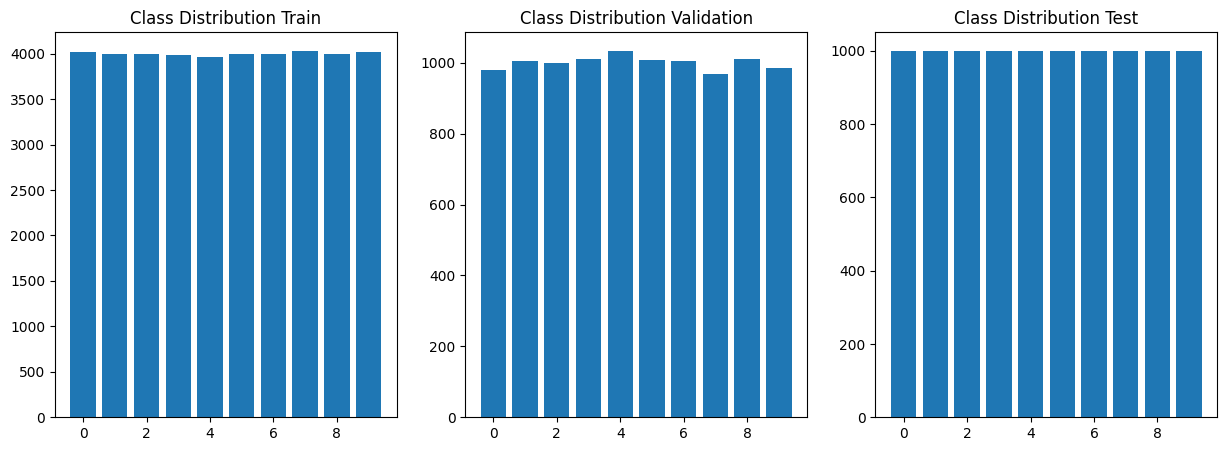

In [497]:
from collections import Counter
from matplotlib import pyplot as plt
import numpy as np

fig, ax = plt.subplots(1,3, figsize=(15,5))

for i, subfolder in enumerate([train_splitset, val_splitset, test_dataset]):
    label_counts = Counter(label for _, label in subfolder)
    labels, counts = zip(*label_counts.items())
    ax[i].bar(labels, counts)
    ax[i].set_title(f'Class Distribution {["Train", "Validation", "Test"][i]}')
    print(f"Subset {['Train', 'Validation', 'Test'][i]}: {label_counts}")


plt.savefig("./models/label_distribution.png")
plt.show()


### Visualize dataset

Visualize sample of dataset

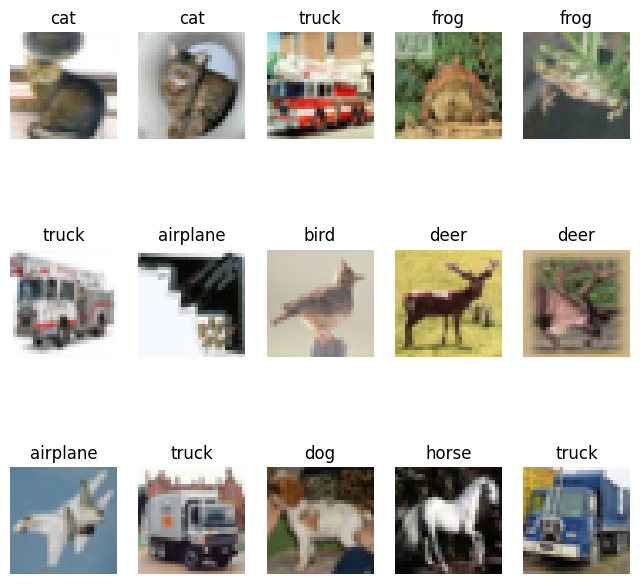

In [498]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(3, 5, figsize=(8, 8))
ax = ax.flatten()

for i in range(5):
    img, label = train_splitset[i]
    ax[i].imshow(img.permute(1, 2, 0))
    ax[i].set_title(train_splitset.dataset.classes[label])
    ax[i].axis('off')
for j in range(5, 10):
    img, label = val_splitset[j]
    ax[j].imshow(img.permute(1, 2, 0))
    ax[j].set_title(val_splitset.dataset.classes[label])
    ax[j].axis('off')
for k in range(10, 15):
    img, label = test_dataset[k]
    ax[k].imshow(img.permute(1, 2, 0))
    ax[k].set_title(test_dataset.classes[label])
    ax[k].axis('off')
plt.show()

### Transform dataset

Normalizing CIFAR-10 images scales pixel values to [-1, 1], centers the data distribution around zero, speeds up Gradient Descent convergence, and stabilizes training across layers

In [499]:
# normalization to [-1, 1] from [0, 1]

import torchvision.transforms as transforms

transform_cifar = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

print(f"Sample before normalization: {train_splitset[4][0]}")

train_splitset.dataset.transform = transform_cifar
val_splitset.dataset.transform = transform_cifar
test_dataset.transform = transform_cifar

print(f"Sample after normalization: {train_splitset[4][0]}")

Sample before normalization: tensor([[[0.4745, 0.4745, 0.4745,  ..., 0.4941, 0.4353, 0.4745],
         [0.4471, 0.4392, 0.4471,  ..., 0.5176, 0.4118, 0.4510],
         [0.4118, 0.4118, 0.4314,  ..., 0.5255, 0.4392, 0.4627],
         ...,
         [0.2392, 0.2627, 0.2667,  ..., 0.2588, 0.2431, 0.2314],
         [0.2549, 0.2745, 0.2745,  ..., 0.2510, 0.2314, 0.2235],
         [0.2745, 0.2784, 0.2745,  ..., 0.2510, 0.2314, 0.2235]],

        [[0.4392, 0.4392, 0.4392,  ..., 0.4902, 0.5569, 0.5922],
         [0.4235, 0.4118, 0.4196,  ..., 0.4980, 0.4863, 0.4784],
         [0.3961, 0.3961, 0.4196,  ..., 0.5098, 0.5098, 0.4706],
         ...,
         [0.2196, 0.2235, 0.2392,  ..., 0.2863, 0.2980, 0.2980],
         [0.2275, 0.2235, 0.2392,  ..., 0.2784, 0.2902, 0.2902],
         [0.2353, 0.2157, 0.2275,  ..., 0.2784, 0.2863, 0.2902]],

        [[0.4078, 0.4078, 0.4078,  ..., 0.3569, 0.3529, 0.3765],
         [0.4000, 0.3922, 0.4000,  ..., 0.3804, 0.3137, 0.3216],
         [0.3843, 0.3843, 0.4

### DataLoader

In [500]:
# DataLoader

import torch

train_loader = torch.utils.data.DataLoader(
    train_splitset, 
    batch_size=batch_size, 
    shuffle=True,
    num_workers=num_workers,
    pin_memory=True
)

val_loader = torch.utils.data.DataLoader(
    val_splitset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=True
)

test_loader = torch.utils.data.DataLoader(
    test_dataset, 
    batch_size=batch_size, 
    shuffle=False,
    num_workers=num_workers,
    pin_memory=True
)

## Cross Entropy Loss by torch

Loss function:
- Cross entropy is used to measure the difference between the true label distribution and the predicted probability distribution:
  L = - Σ y_i log(p_i)
- In the case of integer labels (from 0 to 9), sparse categorical cross entropy is applied:
  L = -log(p_correct_class) means one-hot label result is use to calculate loss
- Cross entropy strongly penalizes incorrect predictions with high confidence. It is suitable for softmax-based multi-class classification problems

In [501]:
# Prove that CrossEntropyLoss is equivalent to LogSoftmax + NLLLoss (negative log likelihood) in PyTorch

import torch
import torch.nn as nn

# create sample logits and labels
logits = torch.tensor([[2.0, 1.0, 0.1]]) # batch size = 1, 3 classes
label = torch.tensor([0])               # batch size = 1, correct class is 0

# Case 1 : using nn.CrossEntropyLoss (Softmax + NLLLoss)
ce_lossfunc = nn.CrossEntropyLoss()
ce_loss = ce_lossfunc(logits, label)

# Case 2 : manual calculate
## logits -> log(softmax) -> NLLLoss
logit_softmax = nn.LogSoftmax(dim=1)
nllloss = nn.NLLLoss()
logit_prob = logit_softmax(logits) # probability after softmax
logit_softmax_loss = nllloss(logit_prob, label)

# case 3 : calculate loss directly from logits without using Softmax
logit_loss = nllloss(logits, label)

# print result
print(f"using nn.CrossEntropyLoss : {ce_loss.item():.6f}")
print(f"manually (LogSoftmax + nn.NLLLoss) : {logit_softmax_loss.item():.6f}")
print(f"manually nn.NLLLoss : {logit_loss.item():.6f}")

# Conclusion:
if ce_loss.item() == logit_softmax_loss.item() and ce_loss.item() != logit_loss.item():
    print("CrossEntropyLoss is equivalent to LogSoftmax + NLLLoss")
else:
    print("nn.CrossEntropyLoss is NOT equivalent to manually (LogSoftmax + NLLLoss)")

using nn.CrossEntropyLoss : 0.417030
manually (LogSoftmax + nn.NLLLoss) : 0.417030
manually nn.NLLLoss : -2.000000
CrossEntropyLoss is equivalent to LogSoftmax + NLLLoss


SGD (Stochastic Gradient Descent) is an optimization algorithm that updates network weights iteratively based on the gradient of the loss function computed from a small batch of data

Combined with Momentum to accelerate learning in relevant directions and reduce oscillations across steep ravines. LR (Learning Rate) determines the step size taken towards the minimum at each iteration, where a higher initial value enables faster initial feature exploration. Set the LR large in first training then apply Cosine Annealing LR Scheduler that decreases the learning rate from an initial value to a minimum value following a half‑cosine curve over T_max iterations

Weight Decay applies L2 regularization by penalizing large weights to reduce overfitting and improve model generalization

In [502]:
class modelOptimizer():
    def __init__(self, model, lr):
        self.model = model
        self.lr = lr
        self.optimizer = torch.optim.SGD(self.model.parameters(), lr=self.lr, momentum=mm, weight_decay=weight_decay)
        # self.scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(self.optimizer, T_max=T_max, eta_min=eta_min)
        self.scheduler = torch.optim.lr_scheduler.StepLR(self.optimizer, step_size=step_size_e3, gamma=gamma)
    def zero_grad(self):
        self.optimizer.zero_grad(set_to_none=True)

    def step(self):
        self.optimizer.step()
    
    def scheduler_step(self):
        self.scheduler.step()

## Linear projection

In [503]:
class CustomLinearProjection(torch.nn.Module):
    def __init__(self, in_features, out_features, fix_weights=None, bias=False):
        super().__init__()

        assert in_features > 0, "[ERROR] in_features must be greater than zero"
        assert out_features > 0, "[ERROR] out_features must be greater than zero"

        self.in_features = in_features
        self.out_features = out_features
        self.bias = bias
        self.fix_weights = fix_weights

        if self.fix_weights is not None:
            assert isinstance(self.fix_weights, dict), "[ERROR] fix_weights must be a dictionary"
            assert self.fix_weights['weights'] is not None, "[ERROR] fix_weights must contain 'weights'"
            assert self.fix_weights['weights'].ndim == 2, "[ERROR] fix_weights['weights'] must be a 2D tensor"
        
            if self.bias is True:
                assert self.fix_weights['bias'] is not None, "[ERROR] fix_weights must contain 'bias'"
                assert self.fix_weights['bias'].ndim == 1, "[ERROR] fix_weights['bias'] must be a 1D tensor"

        # create linear layer with in_features and out_features
        self.linear = torch.nn.Linear(self.in_features, self.out_features, bias=self.bias)

        if fix_weights is not None:
            assert isinstance(fix_weights, dict), "[ERROR] fix_weights must be a dict"
            assert 'weights' in fix_weights, "[ERROR] fix_weights must contain 'weights'"
            assert 'bias' in fix_weights, "[ERROR] fix_weights must contain 'bias'"
            assert self.linear.weight is not None, "[ERROR] linear layer has no weight"
            assert fix_weights['weights'].ndim == 2, "[ERROR] fix_weights['weights'] must be a 2D tensor"
            assert fix_weights['weights'].shape == self.linear.weight.shape, "[ERROR] fix_weights['weights'] must have the same shape as the linear layer's weight"

            self.linear.weight = torch.nn.Parameter(
                fix_weights['weights'].clone(),
                requires_grad=False
            )

        if self.bias is True and fix_weights is not None:
            assert 'bias' in fix_weights, "[ERROR] fix_weights must contain 'bias'"
            assert fix_weights['bias'] is not None, "[ERROR] fix_weights must contain 'bias'"
            assert self.linear.bias is not None, "[ERROR] linear layer has no bias"
            assert fix_weights['bias'].ndim == 1, "[ERROR] fix_weights['bias'] must be a 1D tensor"
            assert fix_weights['bias'].shape == self.linear.bias.shape, "[ERROR] fix_weights['bias'] must have the same shape as the linear layer's bias"

            self.linear.bias = torch.nn.Parameter(
                fix_weights['bias'].clone(),
                requires_grad=False
            )

    def forward(self, x):
        return self.linear(x)

## Scaled Dot Product Attention

In [504]:
class CustomVectorQKV(nn.Module):
    def __init__(
        self,
        in_features,
        d_model,
        num_heads,
        projection=CustomLinearProjection,
        proj_weights=None,
        bias=True
    ):
        super().__init__()
        assert d_model > 0, "[ERROR] d_model must be a positive integer."
        assert num_heads > 0, "[ERROR] num_heads must be a positive integer."
        assert in_features > 0, "[ERROR] in_features must be a positive integer."
        assert d_model % num_heads == 0, "[ERROR] d_model must be divisible by num_heads."

        self.d_head = d_model // num_heads
        self.num_heads = num_heads
        self.in_features = in_features

        assert self.d_head > 0, "[ERROR] d_head must be a positive integer."
        assert in_features > 0, "[ERROR] in_features must be a positive integer."
        
        if proj_weights is not None:
            assert isinstance(proj_weights, dict), "[ERROR] proj_weights must be a dictionary."
            assert 'weights' in proj_weights, "[ERROR] proj_weights must contain 'weights'."
            if bias:
                assert 'bias' in proj_weights, "[ERROR] proj_weights must contain 'bias'."

        self.proj = projection(
            in_features=in_features,
            out_features=d_model,
            fix_weights=proj_weights if proj_weights is not None else None,
            bias=bias
        )

    def forward(self, x):
        assert isinstance(x, torch.Tensor), "[ERROR] Input must be a torch.Tensor."
        assert x.ndim == 3, "[ERROR] Input must be a 3-dimensional tensor."
        assert x.size(-1) == self.in_features, "[ERROR] The last dimension of input must match in_features."

        B, N, _ = x.shape # (B, N, in_features)

        x = self.proj(x) # (B, N, d_model)

        x_reshape = x.reshape(B, N, self.num_heads, self.d_head) # (B, N, num_heads, d_head)
        
        x_transpose = x_reshape.transpose(1, 2) # (B, num_heads, N, d_head)

        return x_transpose

In [505]:
class ScaledDotProductAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.softmax = nn.Softmax(dim=-1)
            
    def _get_score(self, q, k):
        # Step 1 : Compute the scaled dot-product of query and key, then divide by the square root of the head dimension.
        t_qkt = torch.matmul(q, k.transpose(-2, -1)) / (self.d_head ** 0.5)

        # Step 2 : if mask is not None, apply the mask to the scaled dot-product scores.
        if self.mask is not None:
            t_qkt = t_qkt.masked_fill(self.mask == 0, float('-inf'))

        # Step 3 : Apply the softmax function to obtain the attention scores.
        score = self.softmax(t_qkt)
        return score

    def _get_output(self, score):
        # Step 4 : Calculate the attention output by multiplying the attention scores with the value tensor.
        output = torch.matmul(score, self.v)
        return output

    def forward(self, q, k, v, mask=None):
        assert q is not None, "[ERROR] query q must be provided."
        assert k is not None, "[ERROR] key k must be provided."
        assert v is not None, "[ERROR] value v must be provided."
        assert isinstance(q, torch.Tensor), "[ERROR] query q must be a torch.Tensor."
        assert isinstance(k, torch.Tensor), "[ERROR] key k must be a torch.Tensor."
        assert isinstance(v, torch.Tensor), "[ERROR] value v must be a torch.Tensor."

        self.q = q
        self.k = k
        self.v = v
        
        assert self.q.size(1) == self.k.size(1) == self.v.size(1), "[ERROR] the number of heads must match."
        assert self.q.size(-1) == self.k.size(-1), "[ERROR] query and key head dimensions must match."
        assert self.k.size(-2) == self.v.size(-2), "[ERROR] key and value sequence lengths must match."
        assert self.q.dim() == self.k.dim() == self.v.dim() == 4, "[ERROR] query q, key k, and value v must be 4-dimensional tensors."
        assert self.q.size(0) == self.k.size(0) == self.v.size(0), "[ERROR] the batch size of query q, key k, and value v must match."

        self.d_head = self.q.size(-1)
        
        assert self.d_head > 0, "[ERROR] the head dimension must be positive."

        if mask is not None:
            assert isinstance(mask, torch.Tensor)
            self.mask = mask
        else:
            self.mask = None

        score = self._get_score(self.q, self.k)
        output = self._get_output(score)
        
        return output
    

## [1] Tokenization

### Patch tokenization

In [506]:
# get patches token as square patches with given patch size
# input shape (B, C, H, W)
# output token shape (B, num_patches, C*patch_height*patch_width)
# # # num_patches = (H // patch_height) * (W // patch_width)

class PatchesTokenization(nn.Module):
    def __init__(self, patches):
        super(PatchesTokenization, self).__init__()
        assert patches is not None and len(patches) == 2 and patches[0] != 0 and patches[1] != 0, "Patches cannot be None and must have length 2 different from zero"
        
        self.patches = patches

    def forward(self, x):
        assert x is not None, "Input tensor x cannot be None"
        assert isinstance(x, torch.Tensor), "Input x must be a torch tensor"
        assert x.dim() == 4, "Input tensor x must be 4-dimensional (B, C, H, W)"
        assert x.shape[0] > 0 and x.shape[1] > 0, "Batch size and number of channels must be greater than zero"
        assert x.shape[2] > 0 and x.shape[3] > 0, "Image height and width must be greater than zero"
        assert x.shape[2] % self.patches[0] == 0 and x.shape[3] % self.patches[1] == 0, "Image dimensions must be divisible by patch size"
        self.x = x
        B, C, H, W = self.x.shape
        patches = []

        n = self.patches[0]
        m = self.patches[1]

        for h in range(0, H, n):
            for w in range(0, W, m):
                patches.append(self.x[:, :, h:h+n, w:w+m]) # get the patch square at position (h, w)

        patches = torch.stack(patches, dim=1) # B*num_patches*C*n*m

        # Flatten each patch
        patches = patches.reshape(B, -1, C * n * m) # B*num_patches*(C*n*m)m, C*n*m is feature dimension of each patch

        return patches

### Pixel tokenization

In [507]:
# get pixel tokens from the input image tensor then combine all channels for each pixel
# input shape (B, C, H, W)
# output token shape (B, H*W, C)

class PixelTokenization(nn.Module):
    def __init__(self):
        super(PixelTokenization, self).__init__()

    def forward(self, x):
        assert x is not None, "Input tensor x cannot be None"
        assert isinstance(x, torch.Tensor), "Input x must be a torch tensor"
        assert x.dim() == 4, "Input tensor x must be 4-dimensional (B, C, H, W)"

        self.x = x
        B, C, H, W = self.x.shape
        pixels = self.x.permute(0, 2, 3, 1)     # (B, H, W, C)
        pixels = pixels.reshape(B, H * W, C) # (B, H*W, C), C is feature dimension of each pixel
        return pixels

### Row tokenization

In [508]:
# get raw tokens (row-wise tokens) from the input image tensor then combine all channels for each row
# input shape (B, C, H, W)
# output token shape (B, H, C*W)

class RowTokenization(nn.Module):
    def __init__(self):
        super(RowTokenization, self).__init__()

    def forward(self, x):
        assert x is not None, "Input tensor x cannot be None"
        assert isinstance(x, torch.Tensor), "Input x must be a torch tensor"
        assert x.dim() == 4, "Input tensor x must be 4-dimensional (B, C, H, W)"

        self.x = x
        B, C, H, W = self.x.shape
        pixels = self.x.permute(0, 2, 3, 1) # (B, H, W, C)
        pixels_by_row = pixels.reshape(B, H, C*W) # (B, H, C*W), each row is a row token, C*W is feature dimension of each row token
        return pixels_by_row

### CNN-stem tokenization

In [509]:
# get spatial tokens from CNN feature maps
# input shape: (B, C, H, W)
# input => CNN => feature maps => tokens
# output tokens: (B, num_spatial,Cout_CNN) where num_spatial = Hout*Wout

class CNNfeatureTokenization(nn.Module):
    def __init__(self, cnn_model: nn.Module):
        super(CNNfeatureTokenization, self).__init__()
        assert cnn_model is not None, "CNN model cannot be None"
        assert isinstance(cnn_model, nn.Module), "CNN model must be an instance of torch.nn.Module"

        self.cnn_model = cnn_model
        # self.cnn_model.eval()  # Set the CNN model to evaluation mode

    def extract_features(self, x):
        # with torch.no_grad():
        _, features = self.cnn_model(x)
        feat_to_token = features["block3"]
        return feat_to_token

    def forward(self, x):
        assert x is not None, "Input tensor x cannot be None"
        assert isinstance(x, torch.Tensor), "Input x must be a torch tensor"
        assert x.dim() == 4, "Input tensor x must be 4-dimensional (B, C, H, W)"

        feat_to_token = self.extract_features(x)  # Extract features using the CNN model
        B, C, H, W = feat_to_token.shape                 # (B, Cout, Hout, Wout)
        tokens = feat_to_token.permute(0, 2, 3, 1)       # (B, Hout, Wout, Cout)
        tokens = tokens.reshape(B, H * W, C) # (B, Hout*Wout, Cout), Cout is feature dimension of each spatial location
        return tokens

Get CNN model architecture

In [510]:
import torch
import torch.nn as nn
import torch.nn.functional as F

KERNEL_SIZE_3 = 3
PADDING_SIZE_1 = 1
STRIDE_SIZE_1 = 1

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, padding, stride):
        super().__init__()

        # using nn.Conv2d will init kernel/weight and bias
        self.conv = nn.Conv2d(in_ch, out_ch, kernel_size, stride, padding)
        self.bn = nn.BatchNorm2d(out_ch)

    # define a forward pipeline with: Conv2D => BatchNorm => ReLU
    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        x = F.relu(x)
        return x

class DeepCNN(nn.Module):
    def __init__(self, visualize_featuremap=False):
        super().__init__()
        self.visualize_featuremap = visualize_featuremap

        # ConvBlock(input channel, output channel, kernel size, padding size, stride size)
        self.block1 = nn.Sequential(
            ConvBlock(3, 96, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1),
            ConvBlock(96, 96, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1),
            ConvBlock(96, 96, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1)
        )
        self.block2 = nn.Sequential(
            ConvBlock(96, 192, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1),
            ConvBlock(192, 192, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1),
            ConvBlock(192, 192, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1)
        )
        self.block3 = nn.Sequential(
            ConvBlock(192, 192, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1),
            ConvBlock(192, 192, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1)
        )

        self.pool = nn.MaxPool2d(2, 2)
        self.gap = nn.AdaptiveAvgPool2d((1,1)) # Global Average Pooling
        self.fc = nn.Linear(192, 10)

    def forward(self, x):
        features = {}
        # block 1: conv + batchnorm + relu
        x = self.pool(self.block1(x))
        features["block1"] = x

        # block 2: conv + batchnorm + relu
        x = self.pool(self.block2(x))
        features["block2"] = x

        # block 3: conv + batchnorm + relu
        x = self.block3(x)
        features["block3"] = x

        x = self.gap(x) # adaptive pooling
        
        x = torch.flatten(x, 1) # flatten

        out = self.fc(x) # output layer

        if self.visualize_featuremap:
            return out, features
        return out

In [511]:
# test a sample input through the CNN model
sample_model_cnnstem = DeepCNN(visualize_featuremap=True).to(device)
sample_input = torch.randn(1, 3, 32, 32).to(device) # batch size 1, 3 channels, 224x224 image

_, feat_sample_in = sample_model_cnnstem(sample_input)
feat_to_token = feat_sample_in['block3'] # (B, C, H, W)

feat_to_token = feat_to_token.permute(0, 2, 3, 1) # (B, H, W, C)
feat_to_token = feat_to_token.reshape(feat_to_token.size(0), -1, feat_to_token.size(-1)) # (B, H*W, C)

print(feat_to_token.shape)

torch.Size([1, 64, 192])


## [2] Build model train container

### Tokenization strategy

In [512]:
sample_model_lstm_patches = DeepCNN(visualize_featuremap=True)
sample_input = torch.randn(1, 3, IMAGE_DIM_H, IMAGE_DIM_W)

with torch.no_grad():
    sample_out, feature_out = sample_model_lstm_patches(sample_input)

feature = feature_out["block3"]

cnnstem_in_feature = feature.shape[1]
cnnstem_num_of_tokens = feature.shape[2] * feature.shape[3]

In [513]:
patches_token_strategy = PatchesTokenization(patches=TOKEN_PATCH_SIZE)
patches_in_feature = IMAGE_DIM_CHANNELS*TOKEN_PATCH_SIZE_H*TOKEN_PATCH_SIZE_W
patches_num_of_tokens = (IMAGE_DIM_H//TOKEN_PATCH_SIZE_H)*(IMAGE_DIM_W//TOKEN_PATCH_SIZE_W)
print("Patch in feature:", patches_in_feature)
print("Patch num of tokens:", patches_num_of_tokens)

rows_token_strategy = RowTokenization()
rows_in_feature = IMAGE_DIM_W*IMAGE_DIM_CHANNELS
rows_num_of_tokens = IMAGE_DIM_H
print("rows in feature:", rows_in_feature)
print("rows num of tokens:", rows_num_of_tokens)

model_lstm_cnnstem_cnnmodel = DeepCNN(visualize_featuremap=True)
cnnstem_token_strategy = CNNfeatureTokenization(model_lstm_cnnstem_cnnmodel)
cnnstem_in_feature = model_lstm_cnnstem_cnnmodel.fc.in_features
cnnstem_num_of_tokens = feat_to_token.shape[1] # same as the number of tokens generated from the CNN stem
print("CNN stem in feature:", cnnstem_in_feature)
print("CNN stem num of tokens:", cnnstem_num_of_tokens)

result_lstm_patches_load['num_tokens'] = patches_num_of_tokens
result_lstm_rows_load['num_tokens'] = rows_num_of_tokens
result_lstm_cnnstem_load['num_tokens'] = cnnstem_num_of_tokens

result_lstm_patches_load['token_dim'] = patches_in_feature
result_lstm_rows_load['token_dim'] = rows_in_feature
result_lstm_cnnstem_load['token_dim'] = cnnstem_in_feature

result_lstm_patches_load['num_tokens'] = patches_num_of_tokens
result_lstm_rows_load['num_tokens'] = rows_num_of_tokens
result_lstm_cnnstem_load['num_tokens'] = cnnstem_num_of_tokens

result_lstm_patches_load['token_dim'] = patches_in_feature
result_lstm_rows_load['token_dim'] = rows_in_feature
result_lstm_cnnstem_load['token_dim'] = cnnstem_in_feature

Patch in feature: 48
Patch num of tokens: 64
rows in feature: 96
rows num of tokens: 32
CNN stem in feature: 192
CNN stem num of tokens: 64


### Embedding token X

In [514]:
class customEmbeddingInputX(nn.Module):
    def __init__(self, d_model, in_features):
        super().__init__()
        self.embedding_layer = nn.Linear(in_features, d_model)

    def forward(self, x):
        return self.embedding_layer(x)

In [515]:
patches_embedding = customEmbeddingInputX(d_model=EMBEDDING_DIM, in_features=patches_in_feature).to(device)
rows_embedding = customEmbeddingInputX(d_model=EMBEDDING_DIM, in_features=rows_in_feature).to(device)
cnnstem_embedding = customEmbeddingInputX(d_model=EMBEDDING_DIM, in_features=cnnstem_in_feature).to(device)

## [3] Image classifier module

### LSTM model

In [516]:
class LSTMImageClassifier(nn.Module):
    def __init__(self, tokenizer, embedding_layer, embedding_dim, hidden_dim, num_layers, num_classes, bidirectional=False):
        super().__init__()

        self.tokenizer = tokenizer
        self.embedding_layer = embedding_layer
        self.bidirectional = bidirectional
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, num_layers, batch_first=True, bidirectional=bidirectional)
        self.classifier = nn.Linear(hidden_dim * (2 if bidirectional else 1), num_classes)

    def forward(self, images_input):
        # Tokenization
        x = self.tokenizer(images_input)

        # Embedding x using the embedding layer
        x = self.embedding_layer(x)

        # LSTM
        output, (h_n, c_n) = self.lstm(x)

        # Last layer's final hidden state
        features = h_n[-1] if not self.bidirectional else torch.cat((h_n[-2], h_n[-1]), dim=1)

        # Classification (basic classification layer)
        logits = self.classifier(features)

        return logits

### GRU model

In [517]:
class GRUImageClassifier(nn.Module):
    def __init__(self, tokenizer, embedding_layer, embedding_dim, hidden_dim, num_layers, num_classes, bidirectional=False):
        super().__init__()

        self.tokenizer = tokenizer
        self.embedding_layer = embedding_layer
        self.bidirectional = bidirectional
        self.gru = nn.GRU(embedding_dim, hidden_dim, num_layers, batch_first=True, bidirectional=bidirectional)
        self.classifier = nn.Linear(hidden_dim * (2 if bidirectional else 1), num_classes)

    def forward(self, images_input):
        # Tokenization
        x = self.tokenizer(images_input)

        # Embedding x using the embedding layer
        x = self.embedding_layer(x)

        # GRU
        output, h_n = self.gru(x)

        # Last layer's final hidden state
        features = h_n[-1] if not self.bidirectional else torch.cat((h_n[-2], h_n[-1]), dim=1)

        # Classification
        logits = self.classifier(features)

        return logits

## [4] LSTM models

### [4.1] LSTM - Patch tokenization

#### Load best model

In [518]:
model_best_lstm_patches = LSTMImageClassifier(
    embedding_layer=patches_embedding,
    tokenizer=patches_token_strategy,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    bidirectional=BIDIRECTIONAL,
    num_classes=NUM_CLASSES
).to(device)

model_last_lstm_patches = LSTMImageClassifier(
    embedding_layer=patches_embedding,
    tokenizer=patches_token_strategy,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    bidirectional=BIDIRECTIONAL,
    num_classes=NUM_CLASSES
).to(device)

result_lstm_patches_load['total_params'] = sum(p.numel() for p in model_best_lstm_patches.parameters())
result_lstm_patches_load['trainable_params'] = sum(p.numel() for p in model_best_lstm_patches.parameters() if p.requires_grad)

In [519]:
from torchmetrics.classification import Accuracy, ConfusionMatrix

model_lstm_patches_loss_func = nn.CrossEntropyLoss() # nn.CrossEntropyLoss combines LogSoftmax and NLLLoss
accuracy_lstm_patches_load = Accuracy(task="multiclass", num_classes=NUM_CLASSES).to(device)
cm_lstm_patches_load = ConfusionMatrix(task="multiclass", num_classes=NUM_CLASSES).to(device)

In [520]:
import torch
checkpoint = torch.load("./models/best_lstm_patches_model.pth") # load the best model checkpoint
model_best_lstm_patches.load_state_dict(checkpoint['model_state_dict']) # load the best model weights
checkpoint_last = torch.load("./models/last_lstm_patches_model.pth") # load the last model checkpoint
model_last_lstm_patches.load_state_dict(checkpoint_last['model_state_dict']) # load the last model weights

C:\Users\pla2hc\AppData\Local\Temp\ipykernel_74592\190270900.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load("./models/best_lstm_patches_model.pt

<All keys matched successfully>

In [521]:
history_lstm_patches_load = checkpoint_last['history']

import json

# reload training time
with open("./models/lstm_patches.json") as f:
    res = json.load(f)

result_lstm_patches_load['train_time'] = res['result']['train_time']

In [522]:
from torchmetrics.classification import Accuracy, ConfusionMatrix

accuracy_lstm_patches = Accuracy(task="multiclass", num_classes=num_class).to(device)
cm_lstm_patches = ConfusionMatrix(task="multiclass", num_classes=num_class).to(device)

#### Execute testing

In [523]:
model_best_lstm_patches.eval()

LSTMImageClassifier(
  (tokenizer): PatchesTokenization()
  (embedding_layer): customEmbeddingInputX(
    (embedding_layer): Linear(in_features=48, out_features=128, bias=True)
  )
  (lstm): LSTM(128, 128, num_layers=3, batch_first=True)
  (classifier): Linear(in_features=128, out_features=10, bias=True)
)

In [524]:
# Testing phase
## test_loss_total : loss calculated on total test samples for the current epoch
## test_sample_total : total number of test samples for the current epoch
## test_loss_mean_batch : loss calculated for the current test batch
## test_cnn_loss_epoch : calculate the average loss for the current epoch
## test_cnn_acc_epoch : calculate the accuracy for the current epoch
import time
test_loss_total, test_sample_total = 0.0, 0.0
test_loss_mean_batch = 0.0

test_preds = []
act_preds = []

start_time = time.time()
with torch.no_grad():
    for batch_idx, (inputs, targets) in enumerate(test_loader):
        inputs, targets = inputs.to(device), targets.to(device)

        output_z = model_best_lstm_patches(inputs) # input => MLP => output logits z

        test_loss_mean_batch = model_lstm_patches_loss_func(output_z, targets)

        test_loss_total += test_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
        predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
        test_sample_total += targets.size(0)
        test_preds.append(predicted.to(device))
        act_preds.append(targets.to(device))

end_test_time = time.time()
result_lstm_patches_load['test_time'] = end_test_time - start_time
result_lstm_patches_load['test_loss'] = test_loss_total / test_sample_total
result_lstm_patches_load['test_acc'] = accuracy_lstm_patches(torch.cat(test_preds), torch.cat(act_preds))*100
cm_lstm_patches_load(torch.cat(test_preds), torch.cat(act_preds))

print(f"[test_loss = {result_lstm_patches_load['test_loss']:.4f}] [test_acc = {result_lstm_patches_load['test_acc']:.2f}%]")

[test_loss = 1.2668] [test_acc = 53.72%]


#### Evaluation

In [525]:
helper_summary_performance(result_lstm_patches_load, history_lstm_patches_load)

Test Performance:
Test Accuracy: 53.71999740600586
Test Loss: 1.266802367210388
Min loss of training set = 1.184730352973938
Min loss of validation set = 1.2675687105178832
Max accuracy of training set = 56.830000000000005
Max accuracy of validation set = 54.059999999999995
Train time = 37:0
Test time = 0:20


### [4.2] LSTM - Rows tokenization

#### Load best model

In [526]:
model_best_lstm_rows = LSTMImageClassifier(
    embedding_layer=rows_embedding,
    tokenizer=rows_token_strategy,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    bidirectional=BIDIRECTIONAL,
    num_classes=NUM_CLASSES
).to(device)

model_last_lstm_rows = LSTMImageClassifier(
    embedding_layer=rows_embedding,
    tokenizer=rows_token_strategy,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    bidirectional=BIDIRECTIONAL,
    num_classes=NUM_CLASSES
).to(device)

result_lstm_rows_load['total_params'] = sum(p.numel() for p in model_best_lstm_rows.parameters())
result_lstm_rows_load['trainable_params'] = sum(p.numel() for p in model_best_lstm_rows.parameters() if p.requires_grad)

In [527]:
from torchmetrics.classification import Accuracy, ConfusionMatrix

model_lstm_rows_loss_func = nn.CrossEntropyLoss() # nn.CrossEntropyLoss combines LogSoftmax and NLLLoss
accuracy_lstm_rows_load = Accuracy(task="multiclass", num_classes=NUM_CLASSES).to(device)
cm_lstm_rows_load = ConfusionMatrix(task="multiclass", num_classes=NUM_CLASSES).to(device)

In [528]:
import torch
checkpoint = torch.load("./models/best_lstm_rows_model.pth") # load the best model checkpoint
model_best_lstm_rows.load_state_dict(checkpoint['model_state_dict']) # load the best model weights
checkpoint_last = torch.load("./models/last_lstm_rows_model.pth") # load the last model checkpoint
model_last_lstm_rows.load_state_dict(checkpoint_last['model_state_dict']) # load the last model weights

C:\Users\pla2hc\AppData\Local\Temp\ipykernel_74592\2780363817.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load("./models/best_lstm_rows_model.pth"

<All keys matched successfully>

In [529]:
history_lstm_rows_load = checkpoint_last['history']

import json

# reload training time
with open("./models/lstm_rows.json") as f:
    res = json.load(f)

result_lstm_rows_load['train_time'] = res['result']['train_time']

In [530]:
from torchmetrics.classification import Accuracy, ConfusionMatrix

accuracy_lstm_rows = Accuracy(task="multiclass", num_classes=num_class).to(device)
cm_lstm_rows = ConfusionMatrix(task="multiclass", num_classes=num_class).to(device)

#### Execute testing

In [531]:
model_best_lstm_rows.eval()

LSTMImageClassifier(
  (tokenizer): RowTokenization()
  (embedding_layer): customEmbeddingInputX(
    (embedding_layer): Linear(in_features=96, out_features=128, bias=True)
  )
  (lstm): LSTM(128, 128, num_layers=3, batch_first=True)
  (classifier): Linear(in_features=128, out_features=10, bias=True)
)

In [532]:
# Testing phase
## test_loss_total : loss calculated on total test samples for the current epoch
## test_sample_total : total number of test samples for the current epoch
## test_loss_mean_batch : loss calculated for the current test batch
## test_cnn_loss_epoch : calculate the average loss for the current epoch
## test_cnn_acc_epoch : calculate the accuracy for the current epoch
import time
test_loss_total, test_sample_total = 0.0, 0.0
test_loss_mean_batch = 0.0

test_preds = []
act_preds = []

start_time = time.time()
with torch.no_grad():
    for batch_idx, (inputs, targets) in enumerate(test_loader):
        inputs, targets = inputs.to(device), targets.to(device)

        output_z = model_best_lstm_rows(inputs) # input => MLP => output logits z

        test_loss_mean_batch = model_lstm_rows_loss_func(output_z, targets)

        test_loss_total += test_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
        predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
        test_sample_total += targets.size(0)
        test_preds.append(predicted.to(device))
        act_preds.append(targets.to(device))

end_test_time = time.time()
result_lstm_rows_load['test_time'] = end_test_time - start_time
result_lstm_rows_load['test_loss'] = test_loss_total / test_sample_total
result_lstm_rows_load['test_acc'] = accuracy_lstm_rows(torch.cat(test_preds), torch.cat(act_preds))*100
cm_lstm_rows(torch.cat(test_preds), torch.cat(act_preds))

print(f"[test_loss = {result_lstm_rows_load['test_loss']:.4f}] [test_acc = {result_lstm_rows_load['test_acc']:.2f}%]")

[test_loss = 1.1692] [test_acc = 58.76%]


#### Evaluation

In [533]:
helper_summary_performance(result_lstm_rows_load, history_lstm_rows_load)

Test Performance:
Test Accuracy: 58.7599983215332
Test Loss: 1.1691695589065552
Min loss of training set = 0.9476523889780044
Min loss of validation set = 1.1710125202178956
Max accuracy of training set = 66.3925
Max accuracy of validation set = 59.0
Train time = 36:52
Test time = 0:20


### [4.3] LSTM - CNN-stem tokenization

#### Load best model

In [534]:
model_best_lstm_cnnstem = LSTMImageClassifier(
    embedding_layer=cnnstem_embedding,
    tokenizer=cnnstem_token_strategy,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    bidirectional=BIDIRECTIONAL,
    num_classes=NUM_CLASSES
).to(device)

model_last_lstm_cnnstem = LSTMImageClassifier(
    embedding_layer=cnnstem_embedding,
    tokenizer=cnnstem_token_strategy,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    bidirectional=BIDIRECTIONAL,
    num_classes=NUM_CLASSES
).to(device)

result_lstm_cnnstem_load['total_params'] = sum(p.numel() for p in model_best_lstm_cnnstem.parameters())
result_lstm_cnnstem_load['trainable_params'] = sum(p.numel() for p in model_best_lstm_cnnstem.parameters() if p.requires_grad)

In [535]:
from torchmetrics.classification import Accuracy, ConfusionMatrix

model_lstm_cnnstem_loss_func = nn.CrossEntropyLoss() # nn.CrossEntropyLoss combines LogSoftmax and NLLLoss
accuracy_lstm_cnnstem_load = Accuracy(task="multiclass", num_classes=NUM_CLASSES).to(device)
cm_lstm_cnnstem_load = ConfusionMatrix(task="multiclass", num_classes=NUM_CLASSES).to(device)

In [536]:
import torch
checkpoint = torch.load("./models/best_lstm_cnnstem_model.pth") # load the best model checkpoint
model_best_lstm_cnnstem.load_state_dict(checkpoint['model_state_dict']) # load the best model weights
checkpoint_last = torch.load("./models/last_lstm_cnnstem_model.pth") # load the last model checkpoint
model_last_lstm_cnnstem.load_state_dict(checkpoint_last['model_state_dict']) # load the last model weights

C:\Users\pla2hc\AppData\Local\Temp\ipykernel_74592\3875862360.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load("./models/best_lstm_cnnstem_model.p

<All keys matched successfully>

In [537]:
history_lstm_cnnstem_load = checkpoint_last['history']

import json

# reload training time
with open("./models/lstm_cnnstem.json") as f:
    res = json.load(f)

result_lstm_cnnstem_load['train_time'] = res['result']['train_time']

In [538]:
from torchmetrics.classification import Accuracy, ConfusionMatrix

accuracy_lstm_cnnstem = Accuracy(task="multiclass", num_classes=num_class).to(device)
cm_lstm_cnnstem = ConfusionMatrix(task="multiclass", num_classes=num_class).to(device)

#### Execute testing

In [539]:
model_best_lstm_cnnstem.eval()

LSTMImageClassifier(
  (tokenizer): CNNfeatureTokenization(
    (cnn_model): DeepCNN(
      (block1): Sequential(
        (0): ConvBlock(
          (conv): Conv2d(3, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (bn): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        )
        (1): ConvBlock(
          (conv): Conv2d(96, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (bn): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        )
        (2): ConvBlock(
          (conv): Conv2d(96, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (bn): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        )
      )
      (block2): Sequential(
        (0): ConvBlock(
          (conv): Conv2d(96, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (bn): BatchNorm2d(192, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
   

In [540]:
# Testing phase
## test_loss_total : loss calculated on total test samples for the current epoch
## test_sample_total : total number of test samples for the current epoch
## test_loss_mean_batch : loss calculated for the current test batch
## test_cnn_loss_epoch : calculate the average loss for the current epoch
## test_cnn_acc_epoch : calculate the accuracy for the current epoch
import time
test_loss_total, test_sample_total = 0.0, 0.0
test_loss_mean_batch = 0.0

test_preds = []
act_preds = []

start_time = time.time()
with torch.no_grad():
    for batch_idx, (inputs, targets) in enumerate(test_loader):
        inputs, targets = inputs.to(device), targets.to(device)

        output_z = model_best_lstm_cnnstem(inputs) # input => MLP => output logits z

        test_loss_mean_batch = model_lstm_cnnstem_loss_func(output_z, targets)

        test_loss_total += test_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
        predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
        test_sample_total += targets.size(0)
        test_preds.append(predicted.to(device))
        act_preds.append(targets.to(device))

end_test_time = time.time()
result_lstm_cnnstem_load['test_time'] = end_test_time - start_time
result_lstm_cnnstem_load['test_loss'] = test_loss_total / test_sample_total
result_lstm_cnnstem_load['test_acc'] = accuracy_lstm_cnnstem(torch.cat(test_preds), torch.cat(act_preds))*100
cm_lstm_cnnstem(torch.cat(test_preds), torch.cat(act_preds))

print(f"[test_loss = {result_lstm_cnnstem_load['test_loss']:.4f}] [test_acc = {result_lstm_cnnstem_load['test_acc']:.2f}%]")

[test_loss = 0.6900] [test_acc = 84.12%]


#### Evaluation

In [541]:
helper_summary_performance(result_lstm_cnnstem_load, history_lstm_cnnstem_load)

Test Performance:
Test Accuracy: 84.12000274658203
Test Loss: 0.690045543050766
Min loss of training set = 0.017160259031690658
Min loss of validation set = 0.4883834833860397
Max accuracy of training set = 99.71
Max accuracy of validation set = 84.67
Train time = 43:11
Test time = 0:20


## [5] GRU models

### [5.1] GRU - Patches tokenization

#### Load best model

In [542]:
# Initialize model
model_best_gru_patches_load = GRUImageClassifier(
    embedding_layer=patches_embedding,
    tokenizer=patches_token_strategy,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    bidirectional=BIDIRECTIONAL,
    num_classes=NUM_CLASSES
).to(device)

model_last_gru_patches_load = GRUImageClassifier(
    embedding_layer=patches_embedding,
    tokenizer=patches_token_strategy,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    bidirectional=BIDIRECTIONAL,
    num_classes=NUM_CLASSES
).to(device)

result_gru_patches_load['total_params'] = sum(p.numel() for p in model_best_gru_patches_load.parameters())
result_gru_patches_load['trainable_params'] = sum(p.numel() for p in model_best_gru_patches_load.parameters() if p.requires_grad)
print("Parameters:", result_gru_patches_load['total_params'])
print("Trainable Parameters:", result_gru_patches_load['trainable_params'])

Parameters: 304778
Trainable Parameters: 304778


In [543]:
import torch
checkpoint = torch.load("./models/best_gru_patches_model.pth") # load the best model checkpoint
model_best_gru_patches_load.load_state_dict(checkpoint['model_state_dict']) # load the best model weights
checkpoint_last = torch.load("./models/last_gru_patches_model.pth") # load the last model checkpoint
model_last_gru_patches_load.load_state_dict(checkpoint_last['model_state_dict']) # load the last model weights

C:\Users\pla2hc\AppData\Local\Temp\ipykernel_74592\1993737118.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load("./models/best_gru_patches_model.pt

<All keys matched successfully>

In [544]:
history_gru_patches_load = checkpoint_last['history']

#### Execute testing

In [545]:
from torchmetrics.classification import Accuracy, ConfusionMatrix

accuracy_gru_patches = Accuracy(task="multiclass", num_classes=NUM_CLASSES).to(device)
cm_gru_patches_load = ConfusionMatrix(task="multiclass", num_classes=NUM_CLASSES).to(device)
model_gru_patches_loss_func = nn.CrossEntropyLoss()

In [546]:
## Testing with best model
model_best_gru_patches_load.eval() # enable evaluation mode

GRUImageClassifier(
  (tokenizer): PatchesTokenization()
  (embedding_layer): customEmbeddingInputX(
    (embedding_layer): Linear(in_features=48, out_features=128, bias=True)
  )
  (gru): GRU(128, 128, num_layers=3, batch_first=True)
  (classifier): Linear(in_features=128, out_features=10, bias=True)
)

In [547]:
# Testing phase
## test_loss_total : loss calculated on total test samples for the current epoch
## test_sample_total : total number of test samples for the current epoch
## test_loss_mean_batch : loss calculated for the current test batch
## test_cnn_loss_epoch : calculate the average loss for the current epoch
## test_cnn_acc_epoch : calculate the accuracy for the current epoch
test_loss_total, test_sample_total = 0.0, 0.0
test_loss_mean_batch = 0.0

test_preds = []
act_preds = []

start_time = time.time()
with torch.no_grad():
    for batch_idx, (inputs, targets) in enumerate(test_loader):
        inputs, targets = inputs.to(device), targets.to(device)

        output_z = model_best_gru_patches_load(inputs) # input => MLP => output logits z

        test_loss_mean_batch = model_gru_patches_loss_func(output_z, targets)

        test_loss_total += test_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
        predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
        test_sample_total += targets.size(0)
        test_preds.append(predicted.to(device))
        act_preds.append(targets.to(device))

end_test_time = time.time()
result_gru_patches_load['test_time'] = end_test_time - start_time
result_gru_patches_load['test_loss'] = test_loss_total / test_sample_total
result_gru_patches_load['test_acc'] = accuracy_gru_patches(torch.cat(test_preds), torch.cat(act_preds))*100
cm_gru_patches_load(torch.cat(test_preds), torch.cat(act_preds))

print(f"[test_loss = {result_gru_patches_load['test_loss']:.4f}] [test_acc = {result_gru_patches_load['test_acc']:.2f}%]")

[test_loss = 1.0327] [test_acc = 62.98%]


#### Evaluation

In [548]:
helper_summary_performance(result_gru_patches_load, history_gru_patches_load)

Test Performance:
Test Accuracy: 62.980003356933594
Test Loss: 1.0327321097373963
Min loss of training set = 0.8680054229974746
Min loss of validation set = 1.0491733531951903
Max accuracy of training set = 68.965
Max accuracy of validation set = 63.41
Train time = 0:0
Test time = 0:20


### [5.2] GRU - Rows tokenization

#### Load best model

In [549]:
# Initialize model
model_best_gru_rows_load = GRUImageClassifier(
    embedding_layer=rows_embedding,
    tokenizer=rows_token_strategy,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    bidirectional=BIDIRECTIONAL,
    num_classes=NUM_CLASSES
).to(device)

model_last_gru_rows_load = GRUImageClassifier(
    embedding_layer=rows_embedding,
    tokenizer=rows_token_strategy,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    bidirectional=BIDIRECTIONAL,
    num_classes=NUM_CLASSES
).to(device)

result_gru_rows_load['total_params'] = sum(p.numel() for p in model_best_gru_rows_load.parameters())
result_gru_rows_load['trainable_params'] = sum(p.numel() for p in model_best_gru_rows_load.parameters() if p.requires_grad)
print("Parameters:", result_gru_rows_load['total_params'])
print("Trainable Parameters:", result_gru_rows_load['trainable_params'])

Parameters: 310922
Trainable Parameters: 310922


In [550]:
import torch
checkpoint = torch.load("./models/best_gru_rows_model.pth") # load the best model checkpoint
model_best_gru_rows_load.load_state_dict(checkpoint['model_state_dict']) # load the best model weights
checkpoint_last = torch.load("./models/last_gru_rows_model.pth") # load the last model checkpoint
model_last_gru_rows_load.load_state_dict(checkpoint_last['model_state_dict']) # load the last model weights

C:\Users\pla2hc\AppData\Local\Temp\ipykernel_74592\1930592718.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load("./models/best_gru_rows_model.pth")

<All keys matched successfully>

In [551]:
history_gru_rows_load = checkpoint_last['history']

#### Execute testing

In [552]:
from torchmetrics.classification import Accuracy, ConfusionMatrix

accuracy_gru_rows = Accuracy(task="multiclass", num_classes=NUM_CLASSES).to(device)
cm_gru_rows_load = ConfusionMatrix(task="multiclass", num_classes=NUM_CLASSES).to(device)
model_gru_rows_loss_func = nn.CrossEntropyLoss()

In [553]:
## Testing with best model
model_best_gru_rows_load.eval() # enable evaluation mode

GRUImageClassifier(
  (tokenizer): RowTokenization()
  (embedding_layer): customEmbeddingInputX(
    (embedding_layer): Linear(in_features=96, out_features=128, bias=True)
  )
  (gru): GRU(128, 128, num_layers=3, batch_first=True)
  (classifier): Linear(in_features=128, out_features=10, bias=True)
)

In [554]:
# Testing phase
## test_loss_total : loss calculated on total test samples for the current epoch
## test_sample_total : total number of test samples for the current epoch
## test_loss_mean_batch : loss calculated for the current test batch
## test_cnn_loss_epoch : calculate the average loss for the current epoch
## test_cnn_acc_epoch : calculate the accuracy for the current epoch
test_loss_total, test_sample_total = 0.0, 0.0
test_loss_mean_batch = 0.0

test_preds = []
act_preds = []

start_time = time.time()
with torch.no_grad():
    for batch_idx, (inputs, targets) in enumerate(test_loader):
        inputs, targets = inputs.to(device), targets.to(device)

        output_z = model_best_gru_rows_load(inputs) # input => MLP => output logits z

        test_loss_mean_batch = model_gru_rows_loss_func(output_z, targets)

        test_loss_total += test_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
        predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
        test_sample_total += targets.size(0)
        test_preds.append(predicted.to(device))
        act_preds.append(targets.to(device))

end_test_time = time.time()
result_gru_rows_load['test_time'] = end_test_time - start_time
result_gru_rows_load['test_loss'] = test_loss_total / test_sample_total
result_gru_rows_load['test_acc'] = accuracy_gru_rows(torch.cat(test_preds), torch.cat(act_preds))*100
cm_gru_rows_load(torch.cat(test_preds), torch.cat(act_preds))

print(f"[test_loss = {result_gru_rows_load['test_loss']:.4f}] [test_acc = {result_gru_rows_load['test_acc']:.2f}%]")

[test_loss = 1.0528] [test_acc = 63.21%]


#### Evaluation

In [555]:
helper_summary_performance(result_gru_rows_load, history_gru_rows_load)

Test Performance:
Test Accuracy: 63.209999084472656
Test Loss: 1.0528409952163695
Min loss of training set = 0.7478809005022049
Min loss of validation set = 1.0487721472740172
Max accuracy of training set = 73.7525
Max accuracy of validation set = 63.42
Train time = 0:0
Test time = 0:20


### [5.3] GRU - CNNstem tokenization

#### Load best model

In [556]:
# Initialize model
model_best_gru_cnnstem_load = GRUImageClassifier(
    embedding_layer=cnnstem_embedding,
    tokenizer=cnnstem_token_strategy,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    bidirectional=BIDIRECTIONAL,
    num_classes=NUM_CLASSES
).to(device)

model_last_gru_cnnstem_load = GRUImageClassifier(
    embedding_layer=cnnstem_embedding,
    tokenizer=cnnstem_token_strategy,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    bidirectional=BIDIRECTIONAL,
    num_classes=NUM_CLASSES
).to(device)

result_gru_cnnstem_load['total_params'] = sum(p.numel() for p in model_best_gru_cnnstem_load.parameters())
result_gru_cnnstem_load['trainable_params'] = sum(p.numel() for p in model_best_gru_cnnstem_load.parameters() if p.requires_grad)
print("Parameters:", result_gru_cnnstem_load['total_params'])
print("Trainable Parameters:", result_gru_cnnstem_load['trainable_params'])

Parameters: 1990356
Trainable Parameters: 1990356


In [557]:
import torch
checkpoint = torch.load("./models/best_gru_cnnstem_model.pth") # load the best model checkpoint
model_best_gru_cnnstem_load.load_state_dict(checkpoint['model_state_dict']) # load the best model weights
checkpoint_last = torch.load("./models/last_gru_cnnstem_model.pth") # load the last model checkpoint
model_last_gru_cnnstem_load.load_state_dict(checkpoint_last['model_state_dict']) # load the last model weights

C:\Users\pla2hc\AppData\Local\Temp\ipykernel_74592\4259047646.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load("./models/best_gru_cnnstem_model.pt

<All keys matched successfully>

In [558]:
history_gru_cnnstem_load = checkpoint_last['history']

#### Execute testing

In [559]:
from torchmetrics.classification import Accuracy, ConfusionMatrix

accuracy_gru_cnnstem = Accuracy(task="multiclass", num_classes=NUM_CLASSES).to(device)
cm_gru_cnnstem_load = ConfusionMatrix(task="multiclass", num_classes=NUM_CLASSES).to(device)
model_gru_cnnstem_loss_func = nn.CrossEntropyLoss()

In [560]:
## Testing with best model
model_best_gru_cnnstem_load.eval() # enable evaluation mode

GRUImageClassifier(
  (tokenizer): CNNfeatureTokenization(
    (cnn_model): DeepCNN(
      (block1): Sequential(
        (0): ConvBlock(
          (conv): Conv2d(3, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (bn): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        )
        (1): ConvBlock(
          (conv): Conv2d(96, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (bn): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        )
        (2): ConvBlock(
          (conv): Conv2d(96, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (bn): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        )
      )
      (block2): Sequential(
        (0): ConvBlock(
          (conv): Conv2d(96, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (bn): BatchNorm2d(192, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    

In [561]:
# Testing phase
## test_loss_total : loss calculated on total test samples for the current epoch
## test_sample_total : total number of test samples for the current epoch
## test_loss_mean_batch : loss calculated for the current test batch
## test_cnn_loss_epoch : calculate the average loss for the current epoch
## test_cnn_acc_epoch : calculate the accuracy for the current epoch
test_loss_total, test_sample_total = 0.0, 0.0
test_loss_mean_batch = 0.0

test_preds = []
act_preds = []

start_time = time.time()
with torch.no_grad():
    for batch_idx, (inputs, targets) in enumerate(test_loader):
        inputs, targets = inputs.to(device), targets.to(device)

        output_z = model_best_gru_cnnstem_load(inputs) # input => MLP => output logits z

        test_loss_mean_batch = model_gru_cnnstem_loss_func(output_z, targets)

        test_loss_total += test_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
        predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
        test_sample_total += targets.size(0)
        test_preds.append(predicted.to(device))
        act_preds.append(targets.to(device))

end_test_time = time.time()
result_gru_cnnstem_load['test_time'] = end_test_time - start_time
result_gru_cnnstem_load['test_loss'] = test_loss_total / test_sample_total
result_gru_cnnstem_load['test_acc'] = accuracy_gru_cnnstem(torch.cat(test_preds), torch.cat(act_preds))*100
cm_gru_cnnstem_load(torch.cat(test_preds), torch.cat(act_preds))

print(f"[test_loss = {result_gru_cnnstem_load['test_loss']:.4f}] [test_acc = {result_gru_cnnstem_load['test_acc']:.2f}%]")

[test_loss = 0.5524] [test_acc = 86.26%]


#### Evaluation

In [562]:
helper_summary_performance(result_gru_cnnstem_load, history_gru_cnnstem_load)

Test Performance:
Test Accuracy: 86.26000213623047
Test Loss: 0.5524388591229915
Min loss of training set = 0.0030745186965912582
Min loss of validation set = 0.4724318599700928
Max accuracy of training set = 99.99249999999999
Max accuracy of validation set = 86.71
Train time = 0:0
Test time = 0:19


## Load base CNN model

pipeline: input => Conv2D => BatchNorm => ReLU => output of layer

In [563]:
import torch.nn as nn
import torch.nn.functional as F

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, padding, stride):
        super().__init__()

        # using nn.Conv2d will init kernel/weight and bias
        self.conv = nn.Conv2d(in_ch, out_ch, kernel_size, stride, padding)
        self.bn = nn.BatchNorm2d(out_ch)

    # define a forward pipeline with: Conv2D => BatchNorm => ReLU
    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        x = F.relu(x)
        return x

In [564]:
KERNEL_SIZE_3 = 3
PADDING_SIZE_1 = 1
STRIDE_SIZE_1 = 1

import torch.nn as nn

class DeepCNN(nn.Module):
    def __init__(self, visualize_featuremap=False):
        super().__init__()
        self.visualize_featuremap = visualize_featuremap

        # ConvBlock(input channel, output channel, kernel size, padding size, stride size)
        self.block1 = nn.Sequential(
            # ConvBlock(3, 32, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1),
            ConvBlock(3, 96, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1),
            ConvBlock(96, 96, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1),
            ConvBlock(96, 96, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1)
        )
        self.block2 = nn.Sequential(
            ConvBlock(96, 192, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1),
            ConvBlock(192, 192, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1),
            ConvBlock(192, 192, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1)
        )
        self.block3 = nn.Sequential(
            ConvBlock(192, 192, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1),
            ConvBlock(192, 192, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1)
        )
        # self.block4 = nn.Sequential(
        #     ConvBlock(128, 256, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1)
        # )

        self.pool = nn.MaxPool2d(2, 2)

        self.gap = nn.AdaptiveAvgPool2d((1,1)) # Global Average Pooling

        # self.fc1 = nn.Linear(256, 128)
        self.fc = nn.Linear(192, 10)

    def forward(self, x):

        features = {}
        # block 1: conv + batchnorm + relu
        x = self.pool(self.block1(x))
        features["block1"] = x

        # block 2: conv + batchnorm + relu
        x = self.pool(self.block2(x))
        features["block2"] = x

        # block 3: conv + batchnorm + relu
        x = self.block3(x)
        features["block3"] = x

        # block 4: conv + batchnorm + relu
        # x = self.block4(x)
        # features["block4"] = x

        # adaptive pooling
        x = self.gap(x)

        # flatten
        x = torch.flatten(x, 1)

        # fully connected layers
        # x = F.relu(self.fc1(x))

        # output layer
        out = self.fc(x)

        if self.visualize_featuremap:
            return out, features
        return out

In [565]:
from torchmetrics.classification import Accuracy, ConfusionMatrix

accuracy_cnn = Accuracy(task="multiclass", num_classes=num_class).to(device)
cm_cnn = ConfusionMatrix(task="multiclass", num_classes=num_class).to(device)
model_cnn_loss_func = nn.CrossEntropyLoss() # nn.CrossEntropyLoss combines LogSoftmax and NLLLoss

### Load model

In [566]:
# Initialize model
model_cnn_best = DeepCNN().to(device) # create a new instance of the model
model_cnn_last = DeepCNN().to(device) # create a new instance of the model

result_cnn_load['total_params'] = sum(p.numel() for p in model_cnn_best.parameters())
print("Parameters:", result_cnn_load['total_params'])

Parameters: 1667146


In [567]:
import torch
import json

checkpoint = torch.load("../E1/models/best_cnn_model.pth") # load the best model checkpoint
model_cnn_best.load_state_dict(checkpoint['model_state_dict']) # load the best model weights
checkpoint_last = torch.load("../E1/models/last_cnn_model.pth") # load the last model checkpoint
model_cnn_last.load_state_dict(checkpoint_last['model_state_dict']) # load the last model weights

C:\Users\pla2hc\AppData\Local\Temp\ipykernel_74592\1745294624.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load("../E1/models/best_cnn_model.pth") 

<All keys matched successfully>

In [568]:
## Testing with best model
model_cnn_best.eval() # enable evaluation mode

DeepCNN(
  (block1): Sequential(
    (0): ConvBlock(
      (conv): Conv2d(3, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): ConvBlock(
      (conv): Conv2d(96, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (2): ConvBlock(
      (conv): Conv2d(96, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
  )
  (block2): Sequential(
    (0): ConvBlock(
      (conv): Conv2d(96, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn): BatchNorm2d(192, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): ConvBlock(
      (conv): Conv2d(192, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn): BatchNorm2d(192, eps=1e-05, mome

In [569]:
history_cnn_load = checkpoint_last['history']

<Figure size 640x480 with 0 Axes>

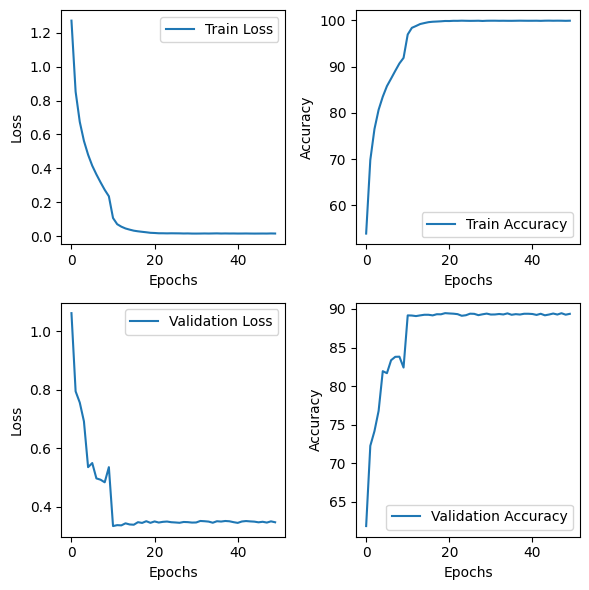

In [570]:
# Visualization of training and validation history

helper_plot_history(history_cnn_load, title_prefix="CNN classifier", savepath="./models/history_cnn.png")

## [EVALUATION COMPARISION]

In [571]:
histories_gru = [history_gru_patches_load, history_gru_rows_load, history_gru_cnnstem_load]
predictions_gru = [result_gru_patches_load, result_gru_rows_load, result_gru_cnnstem_load]
confusionmatrixs_gru = [cm_gru_patches_load, cm_gru_rows_load, cm_gru_cnnstem_load]
model_names_gru = ["GRU-patches", "GRU-rows", "GRU-CNN"]

In [572]:
histories_lstm = [history_lstm_patches_load, history_lstm_rows_load, history_lstm_cnnstem_load]
predictions_lstm = [result_lstm_patches_load, result_lstm_rows_load, result_lstm_cnnstem_load]
confusionmatrixs_lstm = [cm_lstm_patches_load, cm_lstm_rows_load, cm_lstm_cnnstem_load]
model_names_lstm = ["LSTM-patches", "LSTM-rows", "LSTM-CNN"]

In [573]:
histories_patches = [history_lstm_patches_load, history_gru_patches_load]
predictions_patches = [result_lstm_patches_load, result_gru_patches_load]
confusionmatrixs_patches = [cm_lstm_patches_load, cm_gru_patches_load]
model_names_patches = ["LSTM-patches", "GRU-patches"]

In [574]:
histories_rows = [history_lstm_rows_load, history_gru_rows_load]
predictions_rows = [result_lstm_rows_load, result_gru_rows_load]
confusionmatrixs_rows = [cm_lstm_rows_load, cm_gru_rows_load]
model_names_rows = ["LSTM-rows", "GRU-rows"]

In [575]:
histories_cnnstem = [history_lstm_cnnstem_load, history_gru_cnnstem_load]
predictions_cnnstem = [result_lstm_cnnstem_load, result_gru_cnnstem_load]
confusionmatrixs_cnnstem = [cm_lstm_cnnstem_load, cm_gru_cnnstem_load]
model_names_cnnstem = ["LSTM-CNN", "GRU-CNN"]

In [576]:
histories_all = [history_lstm_patches_load, history_gru_patches_load, history_lstm_rows_load, history_gru_rows_load, history_lstm_cnnstem_load, history_gru_cnnstem_load]
predictions_all = [result_lstm_patches_load, result_gru_patches_load, result_lstm_rows_load, result_gru_rows_load, result_lstm_cnnstem_load, result_gru_cnnstem_load]
confusionmatrixs_all = [cm_lstm_patches_load, cm_gru_patches_load, cm_lstm_rows_load, cm_gru_rows_load, cm_lstm_cnnstem_load, cm_gru_cnnstem_load]
model_names_all = ["LSTM-patches", "GRU-patches", "LSTM-rows", "GRU-rows", "LSTM-CNN", "GRU-CNN"]

In [577]:
histories_cnn_compare = [history_lstm_cnnstem_load, history_gru_cnnstem_load, history_cnn_load]
predictions_cnn_compare = [result_lstm_cnnstem_load, result_gru_cnnstem_load, result_cnn_load]
model_names_cnn_all = ['LSTM-CNN', 'GRU-CNN', 'CNN-base']

history_all_cnn = [history_lstm_cnnstem_load, history_gru_cnnstem_load, history_cnn_load]
result_all_cnn = [result_lstm_cnnstem_load, result_gru_cnnstem_load, result_cnn_load]

### Capacity/Training time

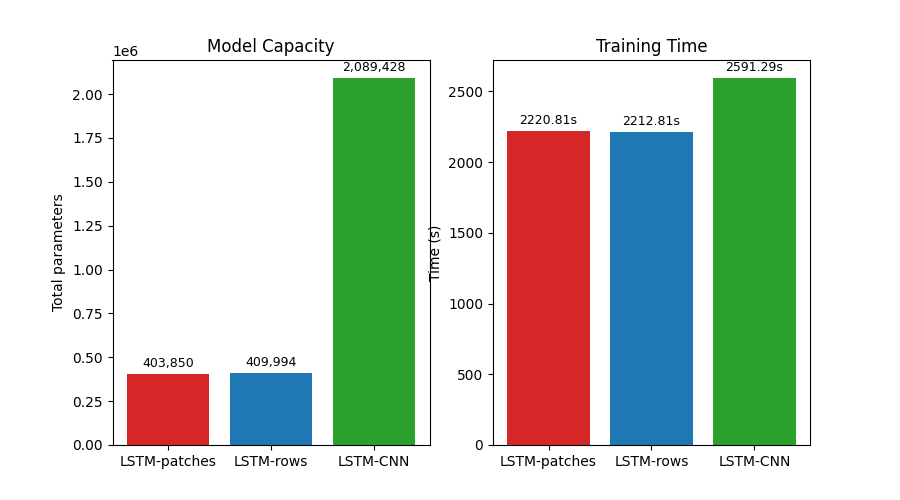

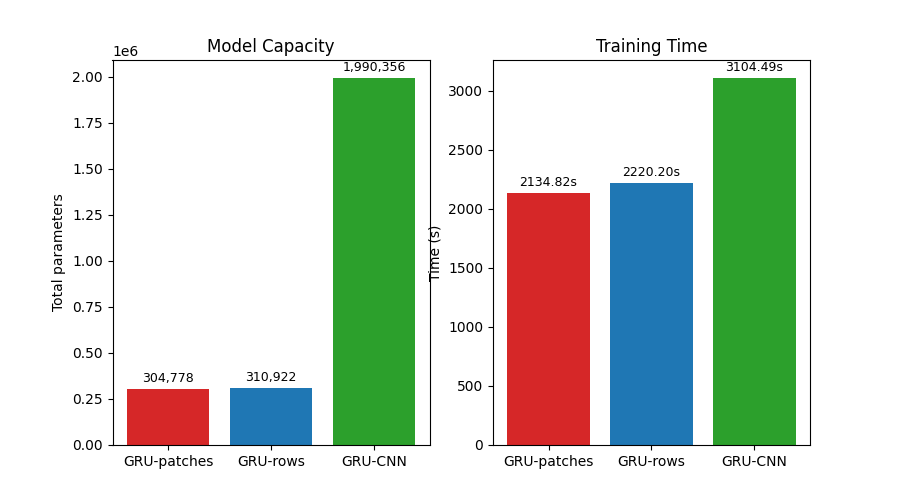

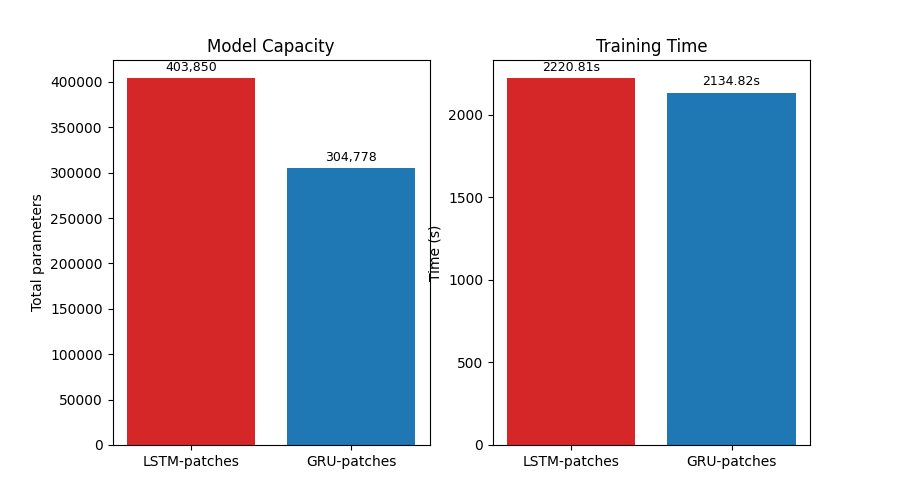

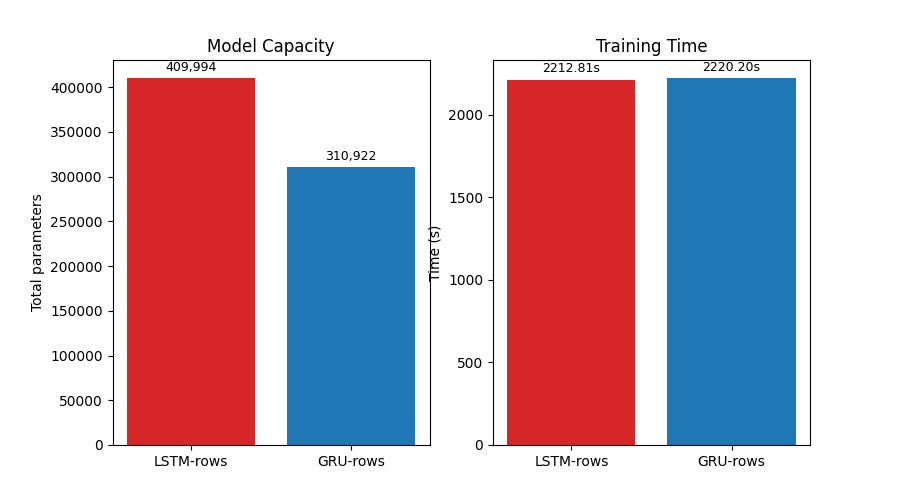

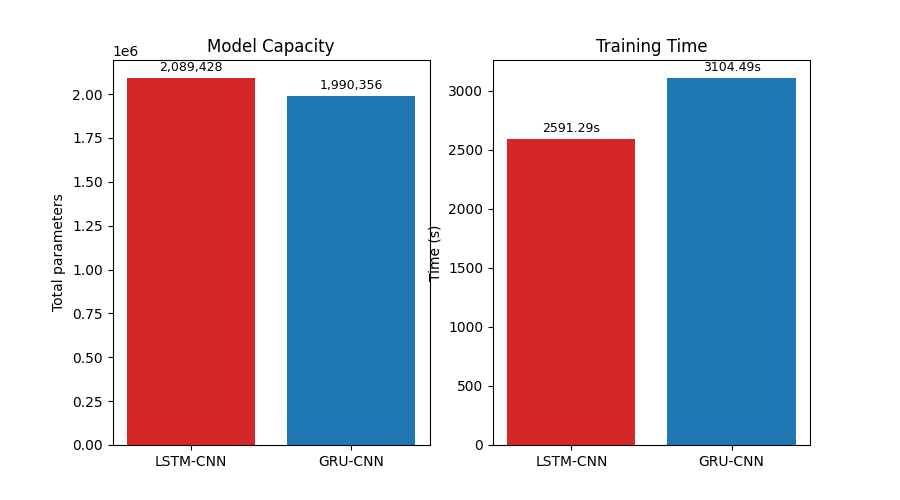

In [578]:
from IPython.display import Image, display

display(Image(filename="./models/cap_time_comparison_lstm.png"))
display(Image(filename="./models/cap_time_comparison_gru.png"))
display(Image(filename="./models/cap_time_comparison_patches.png"))
display(Image(filename="./models/cap_time_comparison_rows.png"))
display(Image(filename="./models/cap_time_comparison_cnnstem.png"))

### Loss/Accuracy visualize

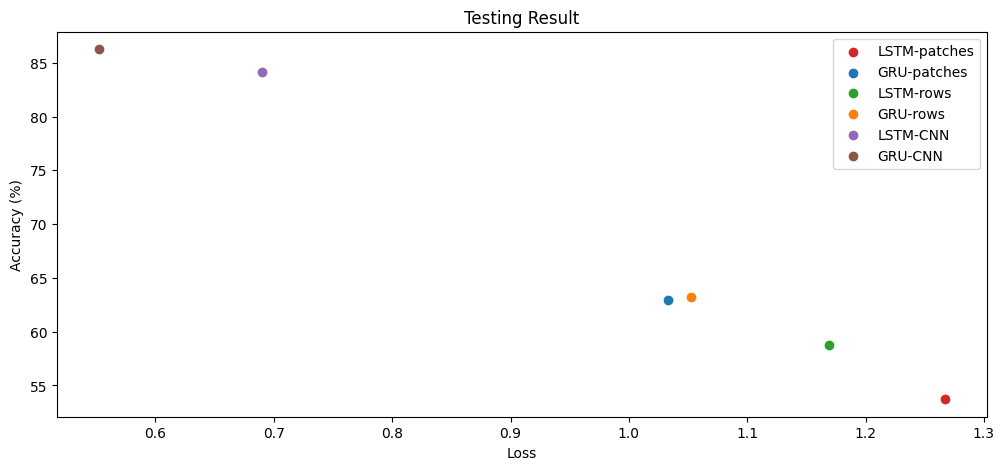

In [579]:
helper_plot_testing_result(predictions_all, model_names_all, savepath="./models/testing_result_accuracy_all.png")

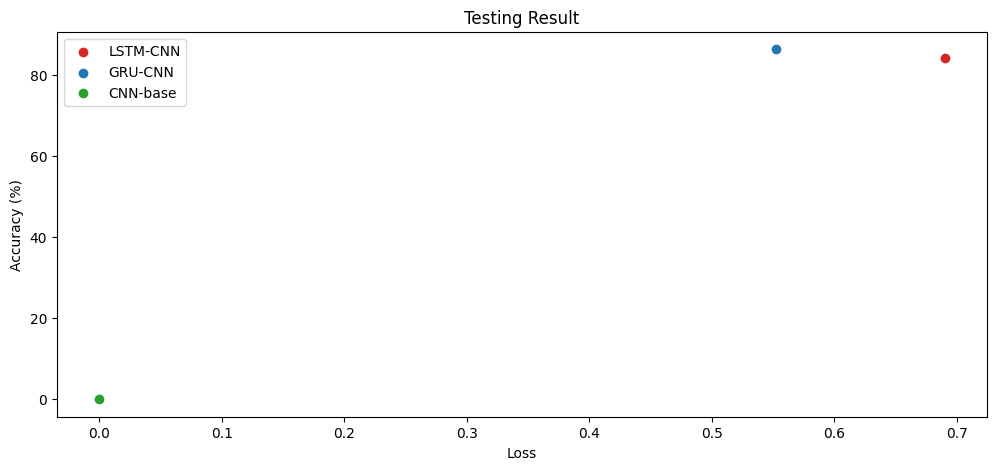

In [580]:
helper_plot_testing_result(predictions_cnn_compare, model_names_cnn_all, savepath="./models/cnnbase_result_accuracy_all.png")

### Loss-Accuracy curve

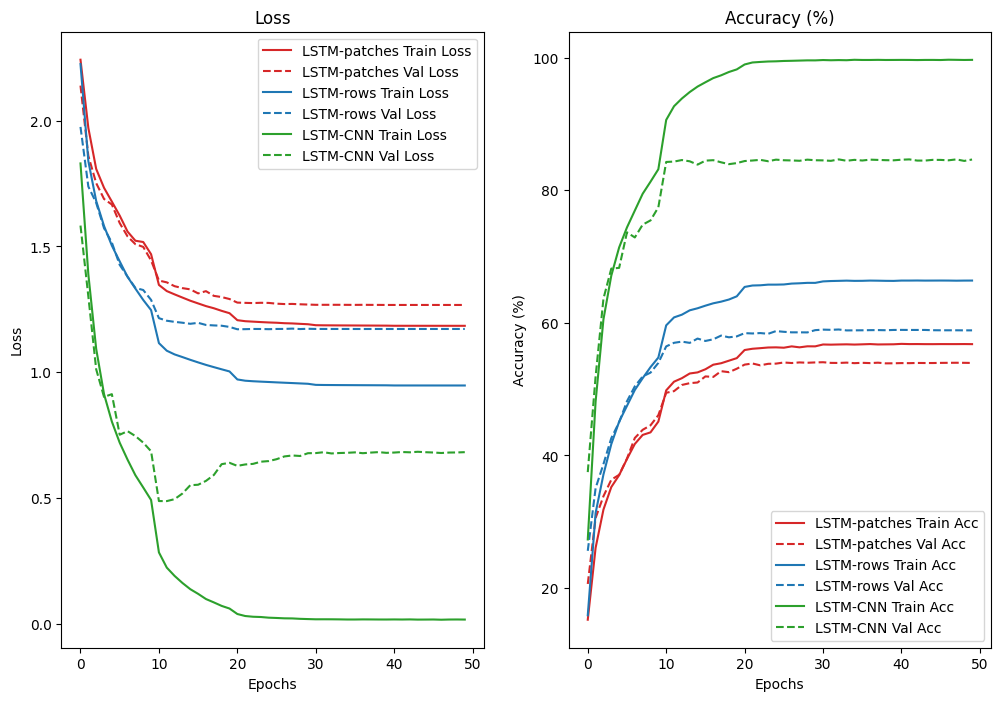

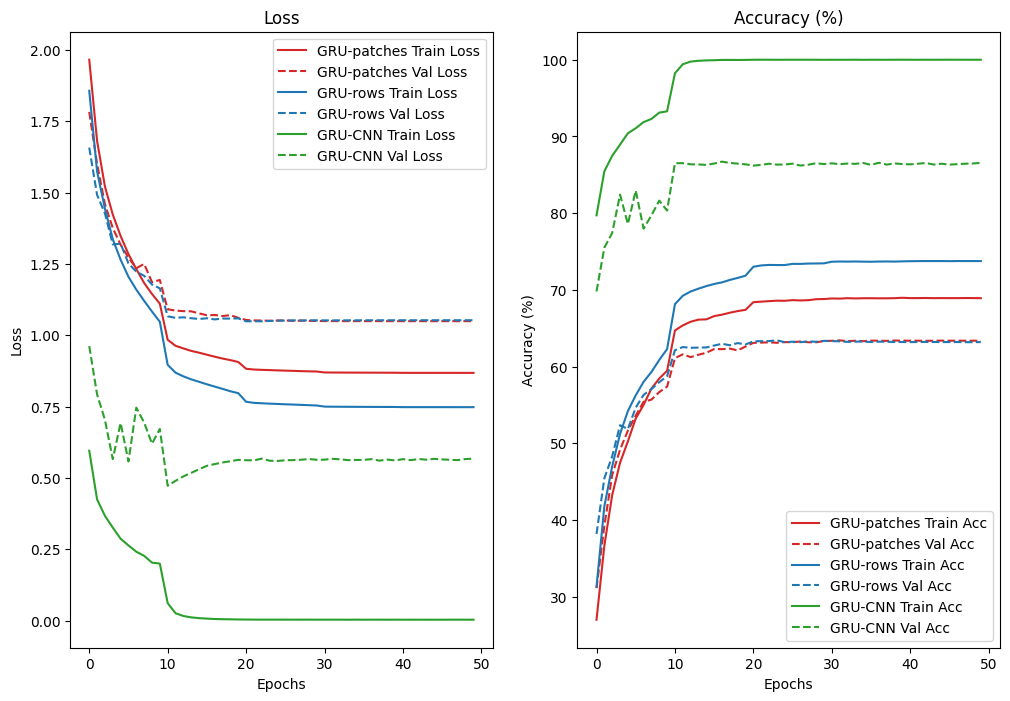

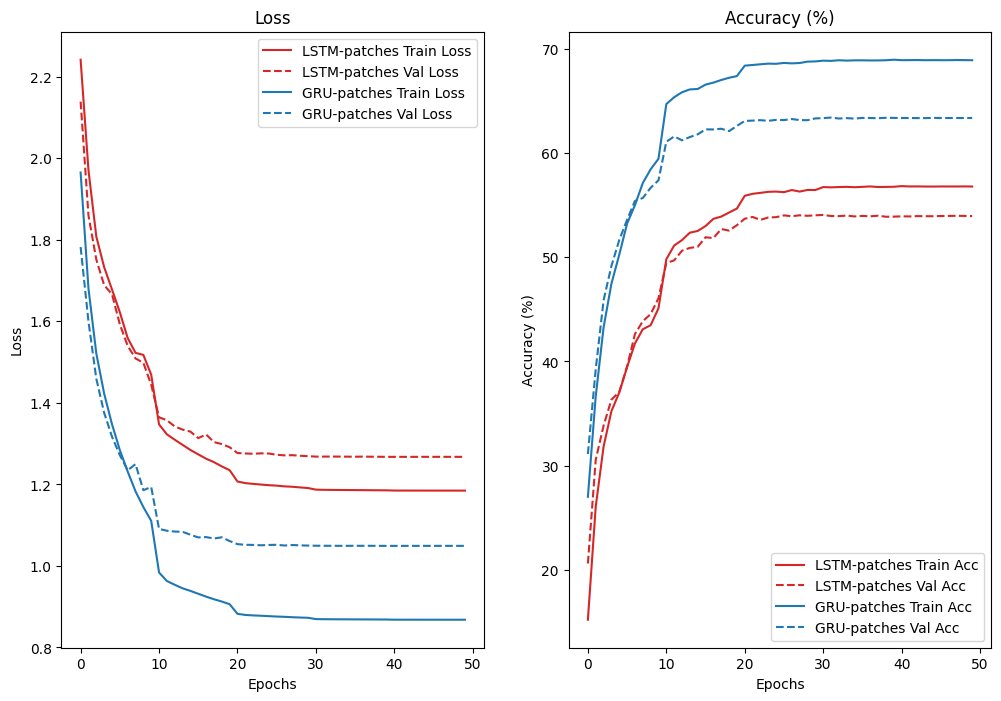

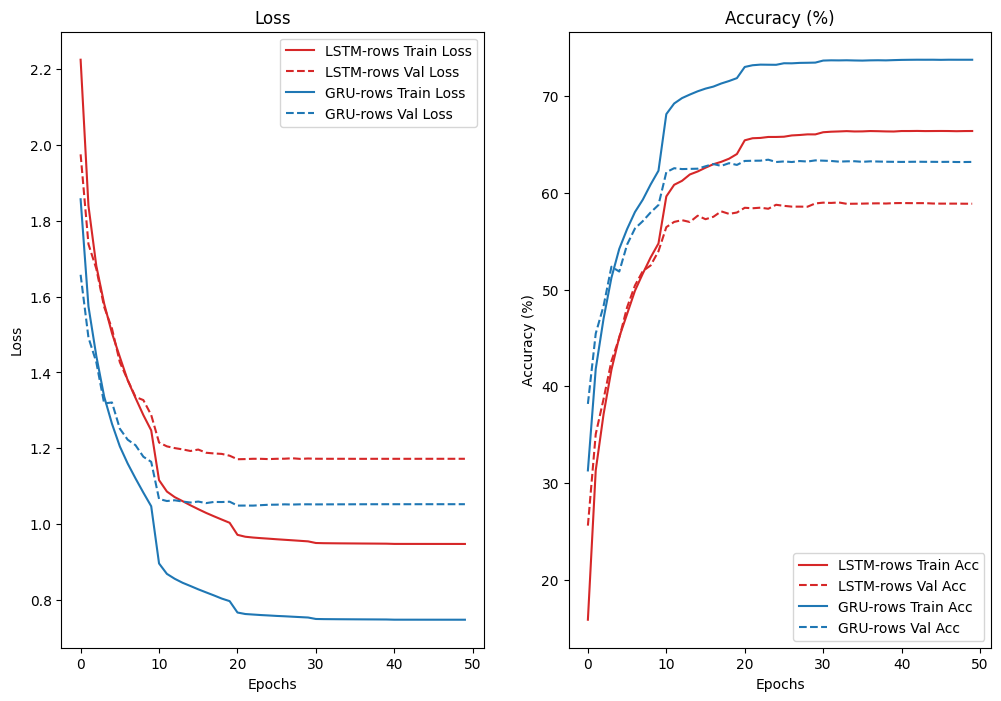

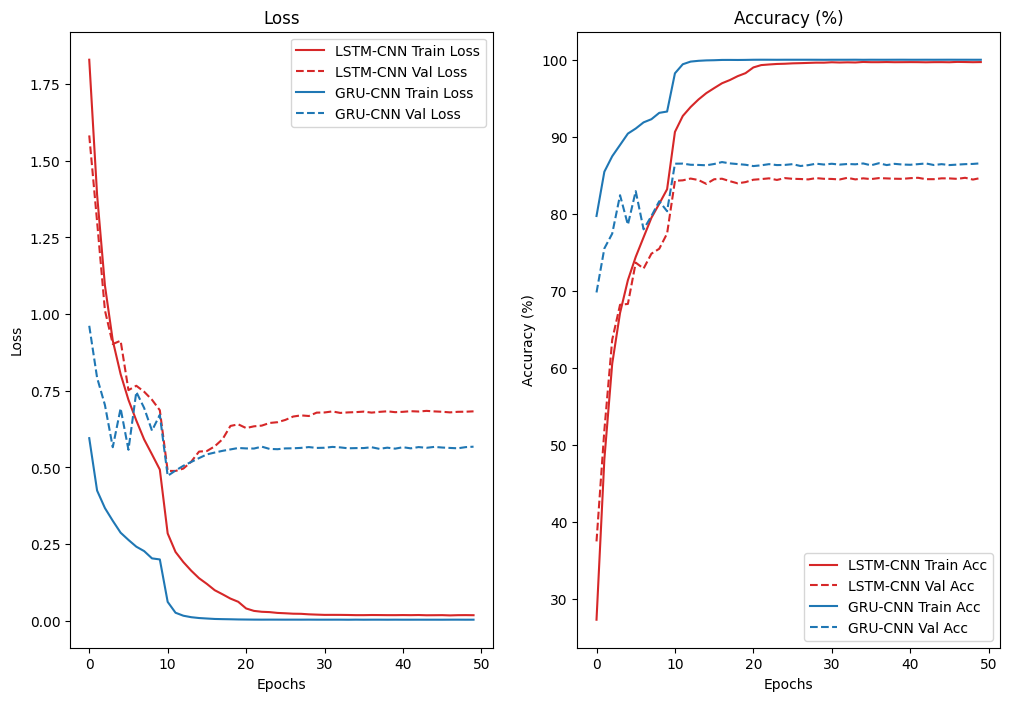

In [581]:
helper_plot_curves(histories_lstm, model_names_lstm, savepath="./models/curves_lstm.png")
helper_plot_curves(histories_gru, model_names_gru, savepath="./models/curves_gru.png")
helper_plot_curves(histories_patches, model_names_patches, savepath="./models/curves_patches.png")
helper_plot_curves(histories_rows, model_names_rows, savepath="./models/curves_rows.png")
helper_plot_curves(histories_cnnstem, model_names_cnnstem, savepath="./models/curves_cnnstem.png")

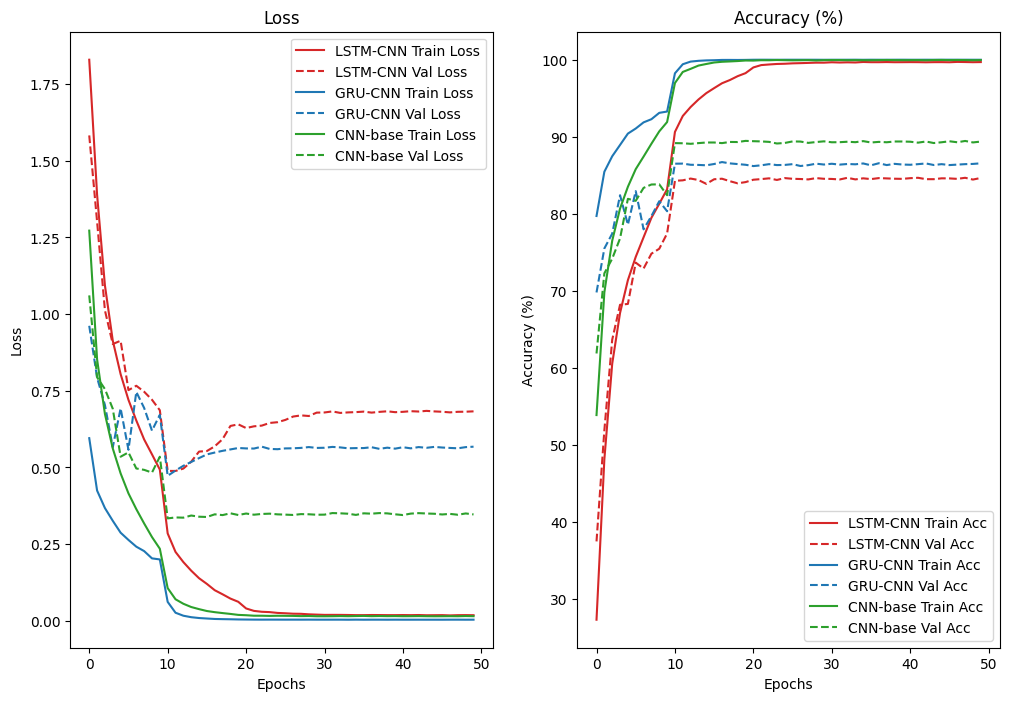

In [582]:
helper_plot_curves(histories_cnn_compare, model_names_cnn_all, savepath="./models/curves_cnnbase.png")

### Confusion matrix

In [583]:
cm_pds = helper_extract_tp_tn_fp_fn(confusionmatrixs_all, predictions_all)

c:\workspace\04_LEARNING\.venv\Lib\site-packages\torchmetrics\utilities\prints.py:43: UserWarning: The ``compute`` method of metric MulticlassConfusionMatrix was called before the ``update`` method which may lead to errors, as metric states have not yet been updated.
  warnings.warn(*args, **kwargs)


In [584]:
predictions_all

[{'test_acc': tensor(53.7200, device='cuda:0'),
  'test_loss': 1.266802367210388,
  'test_time': 20.816551446914673,
  'train_time': 2220.812254667282,
  'tp': tensor([589, 655, 365, 293, 398, 490, 641, 620, 712, 609]),
  'tn': tensor([8620, 8660, 8519, 8450, 8584, 8306, 8477, 8571, 8603, 8582]),
  'fp': tensor([380, 340, 481, 550, 416, 694, 523, 429, 397, 418]),
  'fn': tensor([411, 345, 635, 707, 602, 510, 359, 380, 288, 391]),
  'total_params': 403850,
  'trainable_params': 403850,
  'num_tokens': 64,
  'token_dim': 48,
  'marco_precision': np.float32(0.53246754),
  'marco_recall': np.float32(0.5372),
  'marco_f1': np.float32(0.53295356)},
 {'test_acc': tensor(62.9800, device='cuda:0'),
  'test_loss': 1.0327321097373963,
  'test_time': 20.524216413497925,
  'train_time': 0.0,
  'tp': tensor([674, 753, 514, 383, 562, 528, 711, 682, 775, 716]),
  'tn': tensor([8666, 8741, 8554, 8475, 8624, 8486, 8592, 8704, 8733, 8723]),
  'fp': tensor([334, 259, 446, 525, 376, 514, 408, 296, 267, 277

### Save result

In [585]:
# helper_replace2json(model_lstm_patches_json_path, 'history', clean_for_json(history_lstm_patches))
# helper_replace2json(model_lstm_rows_json_path, 'history', clean_for_json(history_lstm_rows))
# helper_replace2json(model_lstm_cnnstem_json_path, 'history', clean_for_json(history_lstm_cnnstem))

# helper_replace2json(model_lstm_patches_json_path, 'result', clean_for_json(result_lstm_patches))
# helper_replace2json(model_lstm_rows_json_path, 'result', clean_for_json(result_lstm_rows))
# helper_replace2json(model_lstm_cnnstem_json_path, 'result', clean_for_json(result_lstm_cnnstem))

# helper_replace2json(model_gru_patches_json_path, 'history', clean_for_json(history_gru_patches))
# helper_replace2json(model_gru_rows_json_path, 'history', clean_for_json(history_gru_rows))
# helper_replace2json(model_gru_cnnstem_json_path, 'history', clean_for_json(history_gru_cnnstem))

# helper_replace2json(model_gru_patches_json_path, 'result', clean_for_json(result_gru_patches))
# helper_replace2json(model_gru_rows_json_path, 'result', clean_for_json(result_gru_rows))
# helper_replace2json(model_gru_cnnstem_json_path, 'result', clean_for_json(result_gru_cnnstem))

### Show model capacity

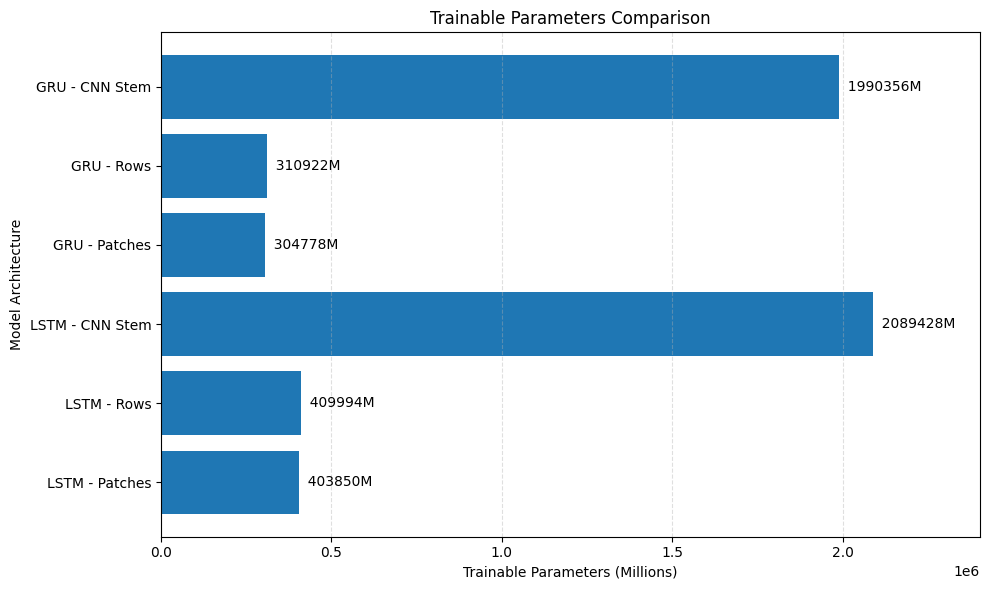

In [588]:
capacity_lstm_patches = result_lstm_patches_load['trainable_params']
capacity_lstm_rows = result_lstm_rows_load['trainable_params']
capacity_lstm_cnnstem = result_lstm_cnnstem_load['trainable_params']
capacity_gru_patches = result_gru_patches_load['trainable_params']
capacity_gru_rows = result_gru_rows_load['trainable_params']
capacity_gru_cnnstem = result_gru_cnnstem_load['trainable_params']

import matplotlib.pyplot as plt

models = [
    "LSTM - Patches",
    "LSTM - Rows",
    "LSTM - CNN Stem",
    "GRU - Patches",
    "GRU - Rows",
    "GRU - CNN Stem"
]

capacities = [
    capacity_lstm_patches,
    capacity_lstm_rows,
    capacity_lstm_cnnstem,
    capacity_gru_patches,
    capacity_gru_rows,
    capacity_gru_cnnstem
]

# Convert to millions
capacities_m = [value for value in capacities]

plt.figure(figsize=(10, 6))

bars = plt.barh(models, capacities_m)

# Display values
for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f"  {width}M",
        va="center",
        fontsize=10
    )

plt.xlabel("Trainable Parameters (Millions)")
plt.ylabel("Model Architecture")
plt.title("Trainable Parameters Comparison")

plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.xlim(0, max(capacities_m) * 1.15)
plt.tight_layout()
plt.show()
